# TechStore — Complete Pandas Business Intelligence Project
**Python for Data Science · Pandas project · Parts 3 → 10 (sections 1 → 23)**

Junior Data Analyst at **TechStore**. Three raw files (`sales.csv`, `products.csv`, `customers.csv`) → cleaned data → KPIs → business recommendations.

**How to run**
- *Locally / VS Code / Jupyter*: keep the three CSV files in the `data/` folder next to this notebook and run all cells.
- *Google Colab*: upload the three files (Files panel or `files.upload()`); they land in `/content` — the setup cell finds them automatically.

**Golden rule followed everywhere:** the raw DataFrames `sales`, `products`, `customers` are never modified. All cleaning happens on copies (`sales_clean`, `products_clean`, `customers_clean`), and every cleaning decision is written down.

---
# PART 3 — Environment setup and data importation
## Task 1 — Import libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.options.display.max_columns = 30
pd.options.display.float_format = "{:,.2f}".format
print("pandas version:", pd.__version__)
print("numpy version :", np.__version__)

pandas version: 3.0.5
numpy version : 2.5.3


## Task 2 — Load the CSV files

In [2]:
# Find the folder that contains the files (local 'data/' folder or Colab '/content')
DATA_DIR = "data" if os.path.exists("data/products.csv") else "/content"
SALES_FILE = "sales.csv" if os.path.exists(os.path.join(DATA_DIR, "sales.csv")) else "sales_1000_rows.csv"

sales = pd.read_csv(os.path.join(DATA_DIR, SALES_FILE))
products = pd.read_csv(os.path.join(DATA_DIR, "products.csv"))
customers = pd.read_csv(os.path.join(DATA_DIR, "customers.csv"))

## Task 3 — Initial verification

In [3]:
print("The three datasets have been loaded successfully.\n")
for name, df in {"sales": sales, "products": products, "customers": customers}.items():
    print(f"{name:<10} type={type(df).__name__:<10} is DataFrame={isinstance(df, pd.DataFrame)}  shape={df.shape}")

The three datasets have been loaded successfully.

sales      type=DataFrame  is DataFrame=True  shape=(1003, 10)
products   type=DataFrame  is DataFrame=True  shape=(24, 6)
customers  type=DataFrame  is DataFrame=True  shape=(250, 6)


In [4]:
sales.head()

,Order_ID,Order_Date,Customer_ID,Product_ID,Quantity,Unit_Price,Discount,Payment_Method,Region,Sales_Rep
0,ORD00001,2025-04-26,C0195,P022,1.00,162.72,5.00,Credit Card,East,Maya
1,ORD00002,2025-11-04,C0168,P002,2.00,"1,077.16",5.00,Online,North,Youssef
2,ORD00003,2025-01-13,C0233,P010,5.00,28.27,0.00,Online,West,Ahmed
3,ORD00004,2025-06-12,C0241,P011,3.00,94.08,10.00,Credit Card,East,Ahmed
4,ORD00005,2025-10-20,C0177,P020,1.00,201.39,10.00,Credit Card,West,Maya


In [5]:
products.head()

,Product_ID,Product_Name,Category,Supplier,Cost_Price,List_Price
0,P001,Laptop Pro 14,Computers,Supplier A,850,1250
1,P002,Laptop Air 13,Computers,Supplier A,720,1100
2,P003,Gaming Laptop,Computers,Supplier B,1050,1650
3,P004,Smartphone X,Smartphones,Supplier C,520,850
4,P005,Smartphone Lite,Smartphones,Supplier C,260,420


In [6]:
customers.head()

,Customer_ID,Customer_Name,Age,Gender,City,Customer_Type
0,C0001,Omar Ben Amor,24.00,Male,Sousse,New
1,C0002,Walid Jaziri,52.00,Female,Bizerte,New
2,C0003,Salma Bouazizi,69.00,Male,Tunis,New
3,C0004,Omar Saidi,63.00,Male,Kairouan,Returning
4,C0005,Karim Trabelsi,32.00,Female,Ben Arous,Returning


### Questions — Part 3
1. **CSV file vs DataFrame** — A CSV is a plain-text file on disk (one line = one row, values separated by commas, no types). A DataFrame is a table **in memory** with an index, named columns and **one dtype per column**, on which pandas can filter, compute and group.
2. **`pd.read_csv()`** reads the file, splits each line into columns, infers the type of each column, turns empty cells / `N/A` into `NaN`, and returns a DataFrame.
3. **`shape` vs `size`** — `shape` = tuple `(rows, columns)` e.g. `(1003, 10)`; `size` = total number of cells = rows × columns = `10030`.
4. **Index** = the label of each row (0, 1, 2… by default). Used by `.loc` and to align rows when combining data.
5. **`index=False`** when exporting avoids writing the index as an extra column (which comes back as `Unnamed: 0` when you reload the file).

---
# PART 4 — Data exploration
## 2 — Exploring the Sales dataset

In [7]:
sales.head(10)

,Order_ID,Order_Date,Customer_ID,Product_ID,Quantity,Unit_Price,Discount,Payment_Method,Region,Sales_Rep
0,ORD00001,2025-04-26,C0195,P022,1.00,162.72,5.00,Credit Card,East,Maya
1,ORD00002,2025-11-04,C0168,P002,2.00,"1,077.16",5.00,Online,North,Youssef
2,ORD00003,2025-01-13,C0233,P010,5.00,28.27,0.00,Online,West,Ahmed
3,ORD00004,2025-06-12,C0241,P011,3.00,94.08,10.00,Credit Card,East,Ahmed
4,ORD00005,2025-10-20,C0177,P020,1.00,201.39,10.00,Credit Card,West,Maya
5,ORD00006,2025-12-14,C0093,P004,1.00,803.15,5.00,Cash,West,Maya
6,ORD00007,2025-04-02,C0150,P011,5.00,94.78,5.00,Online,West,Maya
7,ORD00008,2025-08-26,C0107,P004,5.00,803.76,10.00,Online,East,Ahmed
8,ORD00009,2025-03-11,C0158,P019,2.00,176.86,10.00,Online,North,Maya
9,ORD00010,2025-02-12,C0204,P016,2.00,136.22,0.00,Cash,North,Ahmed


In [8]:
sales.tail(10)

,Order_ID,Order_Date,Customer_ID,Product_ID,Quantity,Unit_Price,Discount,Payment_Method,Region,Sales_Rep
993,ORD00994,2025-07-21,C0072,P021,2.00,133.42,0.00,Bank Transfer,North,Youssef
994,ORD00995,2025-08-23,C0128,P019,1.00,183.38,0.00,Cash,Central,Sara
995,ORD00996,2025-03-19,C0084,P016,3.00,138.95,5.00,Credit Card,East,Youssef
996,ORD00997,2025-09-30,C0007,P008,3.00,176.38,5.00,Cash,Central,Sara
997,ORD00998,2025-10-27,C0212,P009,3.00,480.13,5.00,Online,South,Youssef
998,ORD00999,2025-09-05,C0183,P011,1.00,91.75,15.00,Online,East,Sara
999,ORD01000,2025-07-01,C0131,P016,4.00,127.29,10.00,Online,West,Maya
1000,ORD00018,2025-02-25,C0054,P018,1.00,18.33,0.00,Cash,West,Amine
1001,ORD00204,2025-02-17,C0036,P009,3.00,458.25,10.00,Cash,Central,Sara
1002,ORD00612,2025-04-29,C0171,P023,1.00,232.33,15.00,Online,West,Ahmed


In [9]:
print("Rows:", sales.shape[0], "| Columns:", sales.shape[1])
print(list(sales.columns))

Rows: 1003 | Columns: 10
['Order_ID', 'Order_Date', 'Customer_ID', 'Product_ID', 'Quantity', 'Unit_Price', 'Discount', 'Payment_Method', 'Region', 'Sales_Rep']


In [10]:
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 1003 entries, 0 to 1002
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order_ID        1003 non-null   str    
 1   Order_Date      1003 non-null   str    
 2   Customer_ID     1003 non-null   str    
 3   Product_ID      1003 non-null   str    
 4   Quantity        995 non-null    float64
 5   Unit_Price      997 non-null    float64
 6   Discount        993 non-null    float64
 7   Payment_Method  991 non-null    str    
 8   Region          993 non-null    str    
 9   Sales_Rep       1003 non-null   str    
dtypes: float64(3), str(7)
memory usage: 78.5 KB


In [11]:
sales.describe()

,Quantity,Unit_Price,Discount
count,995.00,997.00,993.00
mean,2.10,360.18,6.23
std,1.28,414.21,6.04
min,1.00,16.93,0.00
25%,1.00,94.83,0.00
50%,2.00,181.11,5.00
75%,3.00,444.82,10.00
max,6.00,"1,740.19",20.00


In [12]:
sales.dtypes

Order_ID              str
Order_Date            str
Customer_ID           str
Product_ID            str
Quantity          float64
Unit_Price        float64
Discount          float64
Payment_Method        str
Region                str
Sales_Rep             str
dtype: object

In [13]:
print("Total number of elements (size):", sales.size)
sales.nunique()

Total number of elements (size): 10030


Order_ID          1000
Order_Date         339
Customer_ID        248
Product_ID          24
Quantity             6
Unit_Price         981
Discount             5
Payment_Method       4
Region               5
Sales_Rep            6
dtype: int64

### Sales questions

In [14]:
dates_tmp = pd.to_datetime(sales["Order_Date"], errors="coerce")   # temporary, raw data stays untouched
print("1. Transactions before cleaning :", len(sales))
print("2. Different customers          :", sales["Customer_ID"].nunique())
print("3. Different products sold      :", sales["Product_ID"].nunique())
print("4. Different regions            :", sales["Region"].nunique())
print("5. Different sales reps         :", sales["Sales_Rep"].nunique())
print("6. Average quantity             :", round(sales["Quantity"].mean(), 2))
print("7. Maximum unit price           :", sales["Unit_Price"].max())
print("8. Minimum unit price           :", sales["Unit_Price"].min())
print("9. Average discount (%)         :", round(sales["Discount"].mean(), 2))
print("10. Oldest transaction date     :", dates_tmp.min().date())

1. Transactions before cleaning : 1003
2. Different customers          : 248
3. Different products sold      : 24
4. Different regions            : 5
5. Different sales reps         : 6
6. Average quantity             : 2.1
7. Maximum unit price           : 1740.19
8. Minimum unit price           : 16.93
9. Average discount (%)         : 6.23
10. Oldest transaction date     : 2025-01-01


## 3 — Exploring Products and Customers
### Products

In [15]:
products.head(10)

,Product_ID,Product_Name,Category,Supplier,Cost_Price,List_Price
0,P001,Laptop Pro 14,Computers,Supplier A,850,1250
1,P002,Laptop Air 13,Computers,Supplier A,720,1100
2,P003,Gaming Laptop,Computers,Supplier B,1050,1650
3,P004,Smartphone X,Smartphones,Supplier C,520,850
4,P005,Smartphone Lite,Smartphones,Supplier C,260,420
5,P006,Tablet Plus,Tablets,Supplier D,230,390
6,P007,Tablet Mini,Tablets,Supplier D,180,310
7,P008,Monitor 24,Monitors,Supplier E,105,180
8,P009,Gaming Monitor 27,Monitors,Supplier E,310,480
9,P010,Wireless Mouse,Accessories,Supplier F,12,28


In [16]:
products.tail(5)

,Product_ID,Product_Name,Category,Supplier,Cost_Price,List_Price
19,P020,Printer,Office Equipment,Supplier I,110,195
20,P021,Router Wi-Fi 6,Networking,Supplier I,70,140
21,P022,Docking Station,Accessories,Supplier F,85,155
22,P023,Graphics Tablet,Computers,Supplier B,125,230
23,P024,Projector,Office Equipment,Supplier I,290,490


In [17]:
print("Products shape:", products.shape)
products.dtypes

Products shape: (24, 6)


Product_ID        str
Product_Name      str
Category          str
Supplier          str
Cost_Price      int64
List_Price      int64
dtype: object

In [18]:
print("Number of categories:", products["Category"].nunique())
print("Categories:", list(products["Category"].unique()))
products["Category"].value_counts()

Number of categories: 10
Categories: ['Computers', 'Smartphones', 'Tablets', 'Monitors', 'Accessories', 'Audio', 'Storage', 'Wearables', 'Office Equipment', 'Networking']


Category
Accessories         6
Computers           4
Smartphones         2
Tablets             2
Monitors            2
Audio               2
Storage             2
Office Equipment    2
Wearables           1
Networking          1
Name: count, dtype: int64

In [19]:
print("Suppliers:", list(products["Supplier"].unique()))
products["Supplier"].value_counts()

Suppliers: ['Supplier A', 'Supplier B', 'Supplier C', 'Supplier D', 'Supplier E', 'Supplier F', 'Supplier G', 'Supplier H', 'Supplier I']


Supplier
Supplier F    4
Supplier C    3
Supplier D    3
Supplier G    3
Supplier I    3
Supplier A    2
Supplier B    2
Supplier E    2
Supplier H    2
Name: count, dtype: int64

In [20]:
print("Average cost price :", round(products["Cost_Price"].mean(), 2))
print("Average list price :", round(products["List_Price"].mean(), 2))
print("Most expensive     :", products.loc[products["List_Price"].idxmax(), "Product_Name"], products["List_Price"].max())
print("Cheapest           :", products.loc[products["List_Price"].idxmin(), "Product_Name"], products["List_Price"].min())
print("Avg (list - cost)  :", round((products["List_Price"] - products["Cost_Price"]).mean(), 2))

Average cost price : 223.42
Average list price : 363.79
Most expensive     : Gaming Laptop 1650
Cheapest           : Phone Case 18
Avg (list - cost)  : 140.38


### Customers

In [21]:
customers.head(10)

,Customer_ID,Customer_Name,Age,Gender,City,Customer_Type
0,C0001,Omar Ben Amor,24.00,Male,Sousse,New
1,C0002,Walid Jaziri,52.00,Female,Bizerte,New
2,C0003,Salma Bouazizi,69.00,Male,Tunis,New
3,C0004,Omar Saidi,63.00,Male,Kairouan,Returning
4,C0005,Karim Trabelsi,32.00,Female,Ben Arous,Returning
5,C0006,Ines Jebali,42.00,Female,NaN,New
6,C0007,Anis Ben Amor,46.00,Female,Sousse,New
7,C0008,Anis Hamdi,31.00,Female,Ariana,Returning
8,C0009,Ines Khaled,32.00,Male,Ariana,New
9,C0010,Rania Chaabane,30.00,Male,Kairouan,Returning


In [22]:
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Customer_ID    250 non-null    str    
 1   Customer_Name  250 non-null    str    
 2   Age            238 non-null    float64
 3   Gender         250 non-null    str    
 4   City           242 non-null    str    
 5   Customer_Type  250 non-null    str    
dtypes: float64(1), str(5)
memory usage: 11.8 KB


In [23]:
print("Average age:", round(customers["Age"].mean(), 1))
print("Youngest:"); print(customers.loc[customers["Age"] == customers["Age"].min(), ["Customer_ID", "Customer_Name", "Age"]])
print("Oldest:");   print(customers.loc[customers["Age"] == customers["Age"].max(), ["Customer_ID", "Customer_Name", "Age"]])

Average age: 45.1
Youngest:
    Customer_ID   Customer_Name   Age
206       C0207  Yasmine Khaled 18.00
Oldest:
    Customer_ID Customer_Name   Age
10        C0011   Ines Gharbi 70.00
54        C0055    Rami Saidi 70.00
190       C0191   Ali Mabrouk 70.00


In [24]:
print(customers["Gender"].value_counts(), "\n")
print(customers["City"].value_counts(), "\n")
print(customers["Customer_Type"].value_counts(), "\n")
print(customers.groupby("Gender")["Age"].mean().round(1))

Gender
Female    135
Male      115
Name: count, dtype: int64 

City
Monastir     26
Bizerte      23
Tunis        23
Mahdia       23
Ariana       21
Nabeul       21
Kairouan     19
Gafsa        18
Gabes        18
Sousse       17
Sfax         17
Ben Arous    16
Name: count, dtype: int64 

Customer_Type
Returning    153
New           97
Name: count, dtype: int64 

Gender
Female   45.10
Male     45.20
Name: Age, dtype: float64


### Business questions — Part 4

In [25]:
print("Category with most products :", products["Category"].value_counts().idxmax(), products["Category"].value_counts().max())
print("Supplier with most products :", products["Supplier"].value_counts().idxmax(), products["Supplier"].value_counts().max())
print("City with most customers    :", customers["City"].value_counts().idxmax(), customers["City"].value_counts().max())
print((customers["Customer_Type"].value_counts(normalize=True) * 100).round(1))

Category with most products : Accessories 6
Supplier with most products : Supplier F 4
City with most customers    : Monastir 26
Customer_Type
Returning   61.20
New         38.80
Name: proportion, dtype: float64


**Answers**
1. **Accessories** is the category with the most products (6 of 24).
2. **Supplier F** provides the most products (4).
3. **Monastir** has the most registered customers (26).
4. **61.2 %** of customers are *Returning* and **38.8 %** are *New* → TechStore already has a loyal base.

---
# PART 5 — Data quality investigation
## 4 — Detecting missing values
### Sales

In [26]:
print("Any missing value?   ", sales.isna().any().any())
print("Total missing values:", sales.isna().sum().sum())
missing = pd.DataFrame({
    "missing": sales.isna().sum(),
    "percent": (sales.isna().mean() * 100).round(2),
}).sort_values("missing", ascending=False)
missing

Any missing value?    True
Total missing values: 46


,missing,percent
Payment_Method,12,1.20
Discount,10,1.00
Region,10,1.00
Quantity,8,0.80
Unit_Price,6,0.60
Order_ID,0,0.00
Order_Date,0,0.00
Product_ID,0,0.00
Customer_ID,0,0.00
Sales_Rep,0,0.00


In [27]:
cols_with_na = sales.columns[sales.isna().any()].tolist()
print("Columns with missing values:", cols_with_na)
rows_with_na = sales[sales.isna().any(axis=1)]
print("Rows with at least one missing value:", len(rows_with_na))
rows_with_na

Columns with missing values: ['Quantity', 'Unit_Price', 'Discount', 'Payment_Method', 'Region']
Rows with at least one missing value: 45


,Order_ID,Order_Date,Customer_ID,Product_ID,Quantity,Unit_Price,Discount,Payment_Method,Region,Sales_Rep
35,ORD00036,2025-01-12,C0240,P021,NaN,134.48,10.00,Credit Card,South,Amine
47,ORD00048,2025-04-01,C0191,P013,1.00,75.54,20.00,Online,NaN,Nour
58,ORD00059,2025-03-16,C0098,P010,2.00,29.26,10.00,Online,NaN,Sara
74,ORD00075,2025-04-29,C0146,P017,2.00,104.16,0.00,NaN,East,Sara
86,ORD00087,2025-04-09,C0046,P018,1.00,16.93,NaN,Online,West,Amine
106,ORD00107,2025-02-07,C0216,P019,2.00,NaN,0.00,Credit Card,East,Amine
110,ORD00111,2025-01-02,C0135,P007,4.00,318.01,NaN,Credit Card,North,Youssef
128,ORD00129,2025-07-19,C0127,P002,1.00,NaN,10.00,Bank Transfer,North,Amine
166,ORD00167,2025-06-18,C0188,P008,NaN,186.61,0.00,Credit Card,West,Maya
171,ORD00172,2025-04-07,C0235,P018,2.00,17.61,NaN,Online,West,Amine


In [28]:
for col in ["Payment_Method", "Region", "Quantity", "Discount", "Unit_Price"]:
    print(f"--- {col} missing: {sales[col].isna().sum()} rows")
    display(sales[sales[col].isna()])

--- Payment_Method missing: 12 rows


,Order_ID,Order_Date,Customer_ID,Product_ID,Quantity,Unit_Price,Discount,Payment_Method,Region,Sales_Rep
74,ORD00075,2025-04-29,C0146,P017,2.00,104.16,0.00,NaN,East,Sara
187,ORD00188,2025-03-20,C0101,P007,2.00,324.36,20.00,NaN,South,Maya
364,ORD00365,2025-07-31,C0041,P019,1.00,175.60,15.00,NaN,South,Youssef
442,ORD00443,2025-09-07,C0114,P001,3.00,"1,257.28",0.00,NaN,North,Nour
496,ORD00497,2025-05-01,C0026,P020,2.00,200.50,0.00,NaN,South,Youssef
531,ORD00532,2025-02-16,C0018,P020,1.00,188.66,5.00,NaN,South,Nour
564,ORD00565,2025-11-24,C0196,P011,1.00,88.67,0.00,NaN,Central,Amine
568,ORD00569,2025-04-23,C0189,P010,3.00,27.75,15.00,NaN,South,Nour
634,ORD00635,2025-02-06,C0241,P002,3.00,"1,074.84",5.00,NaN,West,Youssef
726,ORD00727,2025-02-05,C0028,P004,2.00,801.74,10.00,NaN,Central,Youssef


--- Region missing: 10 rows


,Order_ID,Order_Date,Customer_ID,Product_ID,Quantity,Unit_Price,Discount,Payment_Method,Region,Sales_Rep
47,ORD00048,2025-04-01,C0191,P013,1.00,75.54,20.00,Online,NaN,Nour
58,ORD00059,2025-03-16,C0098,P010,2.00,29.26,10.00,Online,NaN,Sara
305,ORD00306,2025-10-09,C0064,P003,1.00,"1,704.02",0.00,Online,NaN,Youssef
476,ORD00477,2025-12-09,C0137,P013,2.00,77.89,0.00,Credit Card,NaN,Ahmed
511,ORD00512,2025-07-10,C0145,P021,4.00,148.01,0.00,Cash,NaN,Nour
540,ORD00541,2025-08-07,C0184,P007,1.00,315.96,5.00,Bank Transfer,NaN,Amine
667,ORD00668,2025-02-20,C0046,P024,1.00,472.17,5.00,Online,NaN,Youssef
694,ORD00695,2025-09-16,C0099,P023,2.00,238.17,NaN,Online,NaN,Youssef
714,ORD00715,2025-01-11,C0182,P013,1.00,77.84,5.00,Credit Card,NaN,Youssef
777,ORD00778,2025-10-01,C0213,P022,2.00,157.92,15.00,Cash,NaN,Nour


--- Quantity missing: 8 rows


,Order_ID,Order_Date,Customer_ID,Product_ID,Quantity,Unit_Price,Discount,Payment_Method,Region,Sales_Rep
35,ORD00036,2025-01-12,C0240,P021,NaN,134.48,10.00,Credit Card,South,Amine
166,ORD00167,2025-06-18,C0188,P008,NaN,186.61,0.00,Credit Card,West,Maya
189,ORD00190,2025-11-25,C0209,P015,NaN,84.75,5.00,Cash,South,Nour
291,ORD00292,2025-12-06,C0116,P008,NaN,176.26,0.00,Cash,Central,Maya
349,ORD00350,2025-05-09,C0196,P013,NaN,79.08,0.00,Credit Card,West,Youssef
460,ORD00461,2025-02-07,C0105,P009,NaN,471.75,0.00,Online,North,Youssef
537,ORD00538,2025-09-22,C0034,P012,NaN,56.57,15.00,Online,South,Ahmed
932,ORD00933,2025-11-25,C0176,P004,NaN,871.98,15.00,Credit Card,North,Youssef


--- Discount missing: 10 rows


,Order_ID,Order_Date,Customer_ID,Product_ID,Quantity,Unit_Price,Discount,Payment_Method,Region,Sales_Rep
86,ORD00087,2025-04-09,C0046,P018,1.00,16.93,NaN,Online,West,Amine
110,ORD00111,2025-01-02,C0135,P007,4.00,318.01,NaN,Credit Card,North,Youssef
171,ORD00172,2025-04-07,C0235,P018,2.00,17.61,NaN,Online,West,Amine
215,ORD00216,2025-12-29,C0067,P010,1.00,29.14,NaN,Cash,South,Ahmed
379,ORD00380,2025-12-06,C0099,P016,1.00,128.66,NaN,Online,West,Maya
390,ORD00391,2025-03-07,C0064,P011,1.00,91.32,NaN,Cash,South,Ahmed
694,ORD00695,2025-09-16,C0099,P023,2.00,238.17,NaN,Online,NaN,Youssef
695,ORD00696,2025-11-01,C0161,P009,1.00,506.26,NaN,Credit Card,West,Amine
762,ORD00763,2025-02-05,C0144,P009,1.00,482.69,NaN,Online,Central,Ahmed
893,ORD00894,2025-01-18,C0051,P022,1.00,159.43,NaN,Online,East,Amine


--- Unit_Price missing: 6 rows


,Order_ID,Order_Date,Customer_ID,Product_ID,Quantity,Unit_Price,Discount,Payment_Method,Region,Sales_Rep
106,ORD00107,2025-02-07,C0216,P019,2.00,NaN,0.00,Credit Card,East,Amine
128,ORD00129,2025-07-19,C0127,P002,1.00,NaN,10.00,Bank Transfer,North,Amine
200,ORD00201,2025-09-05,C0231,P009,2.00,NaN,15.00,Credit Card,East,Maya
267,ORD00268,2025-12-05,C0173,P018,2.00,NaN,0.00,Online,South,Sara
461,ORD00462,2025-05-04,C0237,P006,5.00,NaN,0.00,Credit Card,South,Nour
946,ORD00947,2025-05-16,C0006,P015,2.00,NaN,5.00,Credit Card,West,Amine


### Customers

In [29]:
print(customers.isna().sum())
print("\nMissing Age :", customers["Age"].isna().sum(), "| Missing City:", customers["City"].isna().sum())
affected = customers[customers["Age"].isna() | customers["City"].isna()]
print("Customers affected:", len(affected), f"({len(affected) / len(customers) * 100:.1f} % of customers)")
print(f"Missing cells: {customers.isna().sum().sum() / customers.size * 100:.2f} % of all customer cells")
affected

Customer_ID       0
Customer_Name     0
Age              12
Gender            0
City              8
Customer_Type     0
dtype: int64

Missing Age : 12 | Missing City: 8
Customers affected: 20 (8.0 % of customers)
Missing cells: 1.33 % of all customer cells


,Customer_ID,Customer_Name,Age,Gender,City,Customer_Type
5,C0006,Ines Jebali,42.00,Female,NaN,New
13,C0014,Fares Hamdi,NaN,Male,Kairouan,New
27,C0028,Rami Ben Salah,NaN,Female,Kairouan,New
66,C0067,Omar Mejri,NaN,Male,Gabes,Returning
70,C0071,Seif Haddad,NaN,Female,Sfax,New
73,C0074,Ali Mansour,20.00,Male,NaN,Returning
74,C0075,Tarek Trabelsi,NaN,Female,Mahdia,Returning
79,C0080,Ines Hamdi,23.00,Male,NaN,New
114,C0115,Mehdi Haddad,NaN,Female,Ariana,New
115,C0116,Rami Bouazizi,NaN,Female,Tunis,Returning


### Analytical questions
1. **Why find missing values first?** pandas silently skips `NaN` in `sum()`/`mean()`, so totals can be wrong without any error, and some operations (`astype(int)`, merges, models) fail or give misleading results.
2. **`isnull()` vs `notnull()`** — `isnull()` is `True` where the value is missing; `notnull()` is the exact opposite (`True` where a value exists).
3. **`isna()` vs `isnull()`** — no difference: two names (aliases) for the same function.
4. **Why not delete every row with a NaN?** We would lose valid information (a missing *Region* does not make the sale fake), we can bias the data (if the missing values are not random) and the revenue would be under-estimated. Only drop when the field is essential and cannot be rebuilt.

## 5 — Handling missing values (on copies!)

In [30]:
sales_clean = sales.copy()
customers_clean = customers.copy()
products_clean = products.copy()

# 1-2. Categorical columns -> most frequent value (mode)
pay_mode = sales_clean["Payment_Method"].mode()[0]
region_mode = sales_clean["Region"].mode()[0]
sales_clean["Payment_Method"] = sales_clean["Payment_Method"].fillna(pay_mode)
sales_clean["Region"] = sales_clean["Region"].fillna(region_mode)
print("Payment mode:", pay_mode, "| Region mode:", region_mode)

Payment mode: Credit Card | Region mode: East


In [31]:
# 3-4. Investigate Quantity
print("Missing quantities:", sales_clean["Quantity"].isna().sum(), "out of", len(sales_clean))
print("Median quantity   :", sales_clean["Quantity"].median())
print(sales_clean["Quantity"].value_counts().sort_index())

Missing quantities: 8 out of 1003
Median quantity   : 2.0
Quantity
1.00    424
2.00    283
3.00    141
4.00     76
5.00     51
6.00     20
Name: count, dtype: int64


**Decision for `Quantity`:** 8 rows (0.8 %) have no quantity. The quantity is **the base of every KPI** (revenue = quantity × price). Filling with the median (2) would *invent* units that maybe were never sold, while removing 8 rows out of 995 changes almost nothing → **we drop these rows** (and write it down).

In [32]:
# DECISION: Quantity is a key field for revenue -> drop the rows (we do not invent sales)
sales_clean = sales_clean.dropna(subset=["Quantity"])

# 5. Missing discount -> 0 (no discount recorded = no discount applied)
sales_clean["Discount"] = sales_clean["Discount"].fillna(0)
print("Rows now:", len(sales_clean))

Rows now: 995


In [33]:
# 6-8. Investigate Unit_Price: is the List_Price a good estimate?
check = sales_clean.merge(products[["Product_ID", "List_Price"]], on="Product_ID", how="left")
ratio = check["Unit_Price"] / check["List_Price"]
print("Unit_Price / List_Price :")
print(ratio.describe().round(3))

Unit_Price / List_Price :
count   989.00
mean      1.00
std       0.03
min       0.94
25%       0.97
50%       1.00
75%       1.03
max       1.06
dtype: float64


**Is `List_Price` a reasonable estimate of a missing `Unit_Price`?** **Yes.** For the 989 sales where both are known, `Unit_Price / List_Price` is between **0.94 and 1.06** (mean 1.00, std 0.03): sellers always sell within ±6 % of the catalogue price. The list price is therefore a much better estimate than a global mean/median (which would mix a 18 TND phone case with a 1,650 TND laptop).

In [34]:
# 9. Apply: fill a missing Unit_Price with the List_Price of the same product
list_price = sales_clean["Product_ID"].map(products.set_index("Product_ID")["List_Price"])
sales_clean["Unit_Price"] = sales_clean["Unit_Price"].fillna(list_price)

# Customers: median age, 'Unknown' city
customers_clean["Age"] = customers_clean["Age"].fillna(customers_clean["Age"].median())
customers_clean["City"] = customers_clean["City"].fillna("Unknown")

# 10. Verify
print("Missing in sales_clean    :", sales_clean.isna().sum().sum())
print("Missing in customers_clean:", customers_clean.isna().sum().sum())
print("Median age used:", customers["Age"].median())

Missing in sales_clean    : 0
Missing in customers_clean: 0
Median age used: 46.0


### Why each strategy (documented decisions)
| Column | Treatment | Reason |
|---|---|---|
| `Payment_Method` | most frequent value | categorical, few rows (1.2 %), the mode is the most likely value and keeps the row's revenue |
| `Region` | most frequent value | same reasoning; the sale is real even if the region was not typed |
| `Quantity` | **drop the rows** | key field: revenue = qty × price. Filling with the median would *invent* sales. Only 8 rows (0.8 %) |
| `Discount` | `0` | an empty discount field usually means "no discount"; 0 is a real business value here (not a fake one) |
| `Unit_Price` | `List_Price` of the product | the selling price is always within ±6 % of the list price → very reasonable estimate |
| `Age` | median | robust to extreme values, does not change the distribution much |
| `City` | `"Unknown"` | we cannot guess a city; a label keeps the customer and stays honest |

## 6 — Detecting duplicate records

In [35]:
print("Duplicated rows:", sales_clean.duplicated().sum())
sales_clean[sales_clean.duplicated(keep=False)].sort_values("Order_ID")

Duplicated rows: 3


,Order_ID,Order_Date,Customer_ID,Product_ID,Quantity,Unit_Price,Discount,Payment_Method,Region,Sales_Rep
17,ORD00018,2025-02-25,C0054,P018,1.00,18.33,0.00,Cash,West,Amine
1000,ORD00018,2025-02-25,C0054,P018,1.00,18.33,0.00,Cash,West,Amine
203,ORD00204,2025-02-17,C0036,P009,3.00,458.25,10.00,Cash,Central,Sara
1001,ORD00204,2025-02-17,C0036,P009,3.00,458.25,10.00,Cash,Central,Sara
611,ORD00612,2025-04-29,C0171,P023,1.00,232.33,15.00,Online,West,Ahmed
1002,ORD00612,2025-04-29,C0171,P023,1.00,232.33,15.00,Online,West,Ahmed


In [36]:
print("Order_IDs appearing more than once:", sales_clean.loc[sales_clean["Order_ID"].duplicated(), "Order_ID"].tolist())
before = len(sales_clean)
sales_clean = sales_clean.drop_duplicates()
print(before, "->", len(sales_clean), "rows after drop_duplicates()")
print("Remaining duplicated rows:", sales_clean.duplicated().sum())
print("Order_ID unique?          ", sales_clean["Order_ID"].is_unique)
print("Duplicated Order_ID left  :", sales_clean["Order_ID"].duplicated().sum())
print("Product_ID unique in products? ", products["Product_ID"].is_unique)
print("Customer_ID unique in customers?", customers["Customer_ID"].is_unique)

Order_IDs appearing more than once: ['ORD00018', 'ORD00204', 'ORD00612']
995 -> 992 rows after drop_duplicates()
Remaining duplicated rows: 0
Order_ID unique?           True
Duplicated Order_ID left  : 0
Product_ID unique in products?  True
Customer_ID unique in customers? True


### Questions
- **Duplicated rows vs duplicated IDs** — a duplicated row is identical in *every* column (a copy). A duplicated ID only shares the key: the other columns can differ (two different sales with the same number = a data-entry/key problem).
- **Why distinguish?** An exact copy can be deleted safely. A duplicated ID with different content must be *investigated* (which one is right? are both real?).
- **If duplicates are not removed** the same sale is counted twice → revenue, quantity and profit are over-estimated and the KPIs are wrong.
- **Products** is a reference table: removing a "duplicate" product without checking could delete a real product or break the link with the sales (every sale must find its product). Here `Product_ID` is unique anyway.

## 7 — Validating data

In [37]:
valid_payments = {"Credit Card", "Online", "Cash", "Bank Transfer"}
valid_regions = {"North", "South", "East", "West", "Central"}
checks = {
    "negative quantities": (sales_clean["Quantity"] < 0).sum(),
    "zero quantities": (sales_clean["Quantity"] == 0).sum(),
    "negative prices": (sales_clean["Unit_Price"] < 0).sum(),
    "zero prices": (sales_clean["Unit_Price"] == 0).sum(),
    "discount < 0": (sales_clean["Discount"] < 0).sum(),
    "discount > 100": (sales_clean["Discount"] > 100).sum(),
    "unexpected payment methods": (~sales_clean["Payment_Method"].isin(valid_payments)).sum(),
    "unexpected regions": (~sales_clean["Region"].isin(valid_regions)).sum(),
    "invalid rep names": (~sales_clean["Sales_Rep"].str.fullmatch(r"[A-Z][a-z]+")).sum(),
    "unknown Product_ID": (~sales_clean["Product_ID"].isin(products["Product_ID"])).sum(),
    "unknown Customer_ID": (~sales_clean["Customer_ID"].isin(customers["Customer_ID"])).sum(),
}
pd.Series(checks, name="problems found")

negative quantities           0
zero quantities               0
negative prices               0
zero prices                   0
discount < 0                  0
discount > 100                0
unexpected payment methods    0
unexpected regions            0
invalid rep names             0
unknown Product_ID            0
unknown Customer_ID           0
Name: problems found, dtype: int64

In [38]:
print("Sales reps:", sorted(sales_clean["Sales_Rep"].unique()))
p_checks = {
    "Cost_Price > List_Price": (products["Cost_Price"] > products["List_Price"]).sum(),
    "missing info": products.isna().any(axis=1).sum(),
    "duplicated Product_ID": products["Product_ID"].duplicated().sum(),
    "missing category": products["Category"].isna().sum(),
}
c_checks = {
    "age < 18": (customers_clean["Age"] < 18).sum(),
    "age > 100": (customers_clean["Age"] > 100).sum(),
    "invalid gender": (~customers_clean["Gender"].isin(["Male", "Female"])).sum(),
    "missing Customer_ID": customers_clean["Customer_ID"].isna().sum(),
}
print(pd.Series(p_checks, name="products"), "\n")
print(pd.Series(c_checks, name="customers"))
print("Categories:", sorted(products["Category"].unique()))

Sales reps: ['Ahmed', 'Amine', 'Maya', 'Nour', 'Sara', 'Youssef']
Cost_Price > List_Price    0
missing info               0
duplicated Product_ID      0
missing category           0
Name: products, dtype: int64 

age < 18               0
age > 100              0
invalid gender         0
missing Customer_ID    0
Name: customers, dtype: int64
Categories: ['Accessories', 'Audio', 'Computers', 'Monitors', 'Networking', 'Office Equipment', 'Smartphones', 'Storage', 'Tablets', 'Wearables']


**Validation result:** no negative/zero quantity or price, all discounts between 0 and 100 %, only the 4 expected payment methods and 5 expected regions, 6 valid rep names, every `Product_ID` / `Customer_ID` of the sales exists in the reference tables, no product sold below cost in the catalogue, all ages between 18 and 70, only `Male`/`Female`. → After treating the missing values and the 3 duplicates the data is **consistent**.

**Cleaning summary:** `sales` 1,003 rows → `sales_clean` **992 rows** (−8 missing quantities, −3 exact duplicates); 0 missing values left.

In [39]:
# Final cleaning task: three clean datasets, originals unchanged
print("sales     :", sales.shape, "->", sales_clean.shape)
print("products  :", products.shape, "->", products_clean.shape)
print("customers :", customers.shape, "->", customers_clean.shape)
print("Raw sales still has", sales.isna().sum().sum(), "missing values (untouched)")

sales     : (1003, 10) -> (992, 10)
products  : (24, 6) -> (24, 6)
customers : (250, 6) -> (250, 6)
Raw sales still has 46 missing values (untouched)


---
# PART 6 — Data types and transformation
## 8 — Working with data types

In [40]:
sales_clean.dtypes

Order_ID              str
Order_Date            str
Customer_ID           str
Product_ID            str
Quantity          float64
Unit_Price        float64
Discount          float64
Payment_Method        str
Region                str
Sales_Rep             str
dtype: object

In [41]:
sales_clean["Order_Date"] = pd.to_datetime(sales_clean["Order_Date"], errors="coerce")
print("Order_Date dtype:", sales_clean["Order_Date"].dtype, "| invalid dates:", sales_clean["Order_Date"].isna().sum())

sales_clean["Quantity"] = sales_clean["Quantity"].astype("int64")          # safe: no NaN left
sales_clean["Unit_Price"] = pd.to_numeric(sales_clean["Unit_Price"])
sales_clean["Discount"] = pd.to_numeric(sales_clean["Discount"])

for col in ["Payment_Method", "Region", "Sales_Rep"]:
    sales_clean[col] = sales_clean[col].astype("category")
for col in ["Category", "Supplier"]:
    products_clean[col] = products_clean[col].astype("category")
for col in ["Gender", "City", "Customer_Type"]:
    customers_clean[col] = customers_clean[col].astype("category")

print(sales_clean.dtypes, "\n")
print(products_clean.dtypes, "\n")
print(customers_clean.dtypes)

Order_Date dtype: datetime64[us] | invalid dates: 0
Order_ID                     str
Order_Date        datetime64[us]
Customer_ID                  str
Product_ID                   str
Quantity                   int64
Unit_Price               float64
Discount                 float64
Payment_Method          category
Region                  category
Sales_Rep               category
dtype: object 

Product_ID           str
Product_Name         str
Category        category
Supplier        category
Cost_Price         int64
List_Price         int64
dtype: object 

Customer_ID           str
Customer_Name         str
Age               float64
Gender           category
City             category
Customer_Type    category
dtype: object


### Questions
- **Date stored as a string** — it is only text: no `.dt.month`, no correct sorting across formats (`"2025-10-01" < "2025-9-01"`), no date filtering or differences between dates.
- **`int64` vs `float64`** — `int64` stores whole numbers only; `float64` stores decimals **and can hold `NaN`**. That is why `Quantity` was read as `float64` (it had NaN) and could be converted to `int64` only *after* treating the missing values.
- **Average of a string column** → `TypeError` (or meaningless concatenation): numbers stored as text must be converted with `pd.to_numeric()` / `astype()` first.

## 9 — Extracting information from dates

In [42]:
d = sales_clean["Order_Date"].dt
sales_clean["Order_Year"] = d.year
sales_clean["Order_Month"] = d.month
sales_clean["Month_Name"] = d.month_name()
sales_clean["Order_Day"] = d.day
sales_clean["Day_Name"] = d.day_name()
sales_clean["Quarter"] = d.quarter
sales_clean["Is_Weekend"] = d.dayofweek >= 5          # 5 = Saturday, 6 = Sunday

season_map = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
              6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"}
sales_clean["Season"] = sales_clean["Order_Month"].map(season_map)

sales_clean[["Order_Date", "Order_Year", "Order_Month", "Month_Name", "Order_Day", "Day_Name", "Quarter", "Is_Weekend", "Season"]].head()

,Order_Date,Order_Year,Order_Month,Month_Name,Order_Day,Day_Name,Quarter,Is_Weekend,Season
0,2025-04-26,2025,4,April,26,Saturday,2,True,Spring
1,2025-11-04,2025,11,November,4,Tuesday,4,False,Autumn
2,2025-01-13,2025,1,January,13,Monday,1,False,Winter
3,2025-06-12,2025,6,June,12,Thursday,2,False,Summer
4,2025-10-20,2025,10,October,20,Monday,4,False,Autumn


In [43]:
print("Weekend transactions:", sales_clean["Is_Weekend"].sum())
print("\nTransactions per month:"); print(sales_clean["Order_Month"].value_counts().sort_index())
print("\nTransactions per quarter:"); print(sales_clean["Quarter"].value_counts().sort_index())
days_count = sales_clean["Day_Name"].value_counts()
print("\nBusiest day of the week:", days_count.idxmax(), "with", days_count.max(), "transactions")
print("\nTransactions per season:"); print(sales_clean["Season"].value_counts())

Weekend transactions: 279

Transactions per month:
Order_Month
1      92
2      80
3      71
4     102
5      92
6      77
7      85
8      68
9      74
10     84
11     79
12     88
Name: count, dtype: int64

Transactions per quarter:
Quarter
1    243
2    271
3    227
4    251
Name: count, dtype: int64

Busiest day of the week: Tuesday with 158 transactions

Transactions per season:
Season
Spring    265
Winter    260
Autumn    237
Summer    230
Name: count, dtype: int64


---
# PART 7 — Selecting, filtering and sorting
## 10 — Selecting columns and rows

In [44]:
s = sales_clean
display(s[["Order_ID", "Order_Date"]].head(3))                 # 1
display(s[["Customer_ID", "Product_ID", "Quantity"]].head(3))  # 2
display(s.drop(columns="Sales_Rep").head(3))                  # 3 all columns except Sales_Rep
display(s.head(10))                                           # 4 first 10 rows

,Order_ID,Order_Date
0,ORD00001,2025-04-26
1,ORD00002,2025-11-04
2,ORD00003,2025-01-13


,Customer_ID,Product_ID,Quantity
0,C0195,P022,1
1,C0168,P002,2
2,C0233,P010,5


,Order_ID,Order_Date,Customer_ID,Product_ID,Quantity,Unit_Price,Discount,Payment_Method,Region,Order_Year,Order_Month,Month_Name,Order_Day,Day_Name,Quarter,Is_Weekend,Season
0,ORD00001,2025-04-26,C0195,P022,1,162.72,5.00,Credit Card,East,2025,4,April,26,Saturday,2,True,Spring
1,ORD00002,2025-11-04,C0168,P002,2,"1,077.16",5.00,Online,North,2025,11,November,4,Tuesday,4,False,Autumn
2,ORD00003,2025-01-13,C0233,P010,5,28.27,0.00,Online,West,2025,1,January,13,Monday,1,False,Winter


,Order_ID,Order_Date,Customer_ID,Product_ID,Quantity,Unit_Price,Discount,Payment_Method,Region,Sales_Rep,Order_Year,Order_Month,Month_Name,Order_Day,Day_Name,Quarter,Is_Weekend,Season
0,ORD00001,2025-04-26,C0195,P022,1,162.72,5.00,Credit Card,East,Maya,2025,4,April,26,Saturday,2,True,Spring
1,ORD00002,2025-11-04,C0168,P002,2,"1,077.16",5.00,Online,North,Youssef,2025,11,November,4,Tuesday,4,False,Autumn
2,ORD00003,2025-01-13,C0233,P010,5,28.27,0.00,Online,West,Ahmed,2025,1,January,13,Monday,1,False,Winter
3,ORD00004,2025-06-12,C0241,P011,3,94.08,10.00,Credit Card,East,Ahmed,2025,6,June,12,Thursday,2,False,Summer
4,ORD00005,2025-10-20,C0177,P020,1,201.39,10.00,Credit Card,West,Maya,2025,10,October,20,Monday,4,False,Autumn
5,ORD00006,2025-12-14,C0093,P004,1,803.15,5.00,Cash,West,Maya,2025,12,December,14,Sunday,4,True,Winter
6,ORD00007,2025-04-02,C0150,P011,5,94.78,5.00,Online,West,Maya,2025,4,April,2,Wednesday,2,False,Spring
7,ORD00008,2025-08-26,C0107,P004,5,803.76,10.00,Online,East,Ahmed,2025,8,August,26,Tuesday,3,False,Summer
8,ORD00009,2025-03-11,C0158,P019,2,176.86,10.00,Online,North,Maya,2025,3,March,11,Tuesday,1,False,Spring
9,ORD00010,2025-02-12,C0204,P016,2,136.22,0.00,Cash,North,Ahmed,2025,2,February,12,Wednesday,1,False,Winter


In [45]:
display(s.iloc[10:31])                    # 5 positions 10 -> 30 (31 is excluded)
display(s.iloc[:, :5].head(3))            # 6 first five columns
display(s.loc[[0, 5, 10], ["Order_ID", "Region", "Sales_Rep"]])   # 7 rows by LABEL
display(s.iloc[[0, 1, 2], [0, 4, 5]])     # 8 rows & columns by POSITION

,Order_ID,Order_Date,Customer_ID,Product_ID,Quantity,Unit_Price,Discount,Payment_Method,Region,Sales_Rep,Order_Year,Order_Month,Month_Name,Order_Day,Day_Name,Quarter,Is_Weekend,Season
10,ORD00011,2025-05-09,C0093,P012,2,56.89,20.00,Credit Card,East,Ahmed,2025,5,May,9,Friday,2,False,Spring
11,ORD00012,2025-11-20,C0127,P010,1,26.82,10.00,Cash,South,Youssef,2025,11,November,20,Thursday,4,False,Autumn
12,ORD00013,2025-09-09,C0012,P004,1,817.30,20.00,Credit Card,West,Maya,2025,9,September,9,Tuesday,3,False,Autumn
13,ORD00014,2025-06-28,C0185,P023,1,236.96,20.00,Online,East,Maya,2025,6,June,28,Saturday,2,True,Summer
14,ORD00015,2025-04-14,C0123,P016,1,129.32,15.00,Credit Card,Central,Nour,2025,4,April,14,Monday,2,False,Spring
15,ORD00016,2025-02-21,C0115,P008,3,179.34,10.00,Credit Card,North,Nour,2025,2,February,21,Friday,1,False,Winter
16,ORD00017,2025-04-09,C0134,P010,1,28.78,10.00,Cash,South,Youssef,2025,4,April,9,Wednesday,2,False,Spring
17,ORD00018,2025-02-25,C0054,P018,1,18.33,0.00,Cash,West,Amine,2025,2,February,25,Tuesday,1,False,Winter
18,ORD00019,2025-03-10,C0150,P018,2,17.37,5.00,Online,North,Ahmed,2025,3,March,10,Monday,1,False,Spring
19,ORD00020,2025-09-08,C0187,P012,1,53.71,10.00,Cash,South,Nour,2025,9,September,8,Monday,3,False,Autumn


,Order_ID,Order_Date,Customer_ID,Product_ID,Quantity
0,ORD00001,2025-04-26,C0195,P022,1
1,ORD00002,2025-11-04,C0168,P002,2
2,ORD00003,2025-01-13,C0233,P010,5


,Order_ID,Region,Sales_Rep
0,ORD00001,East,Maya
5,ORD00006,West,Maya
10,ORD00011,East,Ahmed


,Order_ID,Quantity,Unit_Price
0,ORD00001,1,162.72
1,ORD00002,2,"1,077.16"
2,ORD00003,5,28.27


In [46]:
display(s[s["Customer_ID"] == "C0195"])   # 9 one customer
display(s[s["Product_ID"] == "P001"].head())  # 10 one product

,Order_ID,Order_Date,Customer_ID,Product_ID,Quantity,Unit_Price,Discount,Payment_Method,Region,Sales_Rep,Order_Year,Order_Month,Month_Name,Order_Day,Day_Name,Quarter,Is_Weekend,Season
0,ORD00001,2025-04-26,C0195,P022,1,162.72,5.00,Credit Card,East,Maya,2025,4,April,26,Saturday,2,True,Spring
428,ORD00429,2025-10-09,C0195,P019,1,170.99,0.00,Bank Transfer,East,Nour,2025,10,October,9,Thursday,4,False,Autumn
479,ORD00480,2025-07-16,C0195,P004,4,870.93,10.00,Bank Transfer,West,Maya,2025,7,July,16,Wednesday,3,False,Summer
865,ORD00866,2025-08-02,C0195,P001,1,"1,188.72",0.00,Credit Card,West,Ahmed,2025,8,August,2,Saturday,3,True,Summer


,Order_ID,Order_Date,Customer_ID,Product_ID,Quantity,Unit_Price,Discount,Payment_Method,Region,Sales_Rep,Order_Year,Order_Month,Month_Name,Order_Day,Day_Name,Quarter,Is_Weekend,Season
37,ORD00038,2025-08-13,C0039,P001,1,"1,263.06",5.00,Credit Card,West,Amine,2025,8,August,13,Wednesday,3,False,Summer
89,ORD00090,2025-12-25,C0117,P001,1,"1,252.05",0.00,Credit Card,South,Maya,2025,12,December,25,Thursday,4,False,Winter
137,ORD00138,2025-04-05,C0120,P001,1,"1,280.37",0.00,Credit Card,East,Sara,2025,4,April,5,Saturday,2,True,Spring
170,ORD00171,2025-05-17,C0158,P001,2,"1,230.13",5.00,Online,East,Amine,2025,5,May,17,Saturday,2,True,Spring
201,ORD00202,2025-09-30,C0229,P001,2,"1,268.45",0.00,Credit Card,West,Maya,2025,9,September,30,Tuesday,3,False,Autumn


### `loc` vs `iloc` vs `[]`
- `df["col"]` / `df[["c1","c2"]]` → select **columns**; `df[mask]` → filter **rows** with a boolean condition.
- `df.loc[rows, cols]` → by **labels** (index labels, column names) or a mask. Slices **include** the end: `loc[10:30]` gives labels 10…30.
- `df.iloc[rows, cols]` → by **integer positions** (0, 1, 2…). Slices **exclude** the end: `iloc[10:30]` gives positions 10…29.
- After dropping rows the labels have gaps, so `loc` and `iloc` can return different rows!

## 11 — Filtering with conditions

In [47]:
f = {
    "1 Quantity > 3": s[s["Quantity"] > 3],
    "2 Unit_Price > 500": s[s["Unit_Price"] > 500],
    "3 Discount == 10": s[s["Discount"] == 10],
    "4 Discount > 15": s[s["Discount"] > 15],
    "5 North": s[s["Region"] == "North"],
    "6 South": s[s["Region"] == "South"],
    "7 Cash": s[s["Payment_Method"] == "Cash"],
    "8 Credit Card": s[s["Payment_Method"] == "Credit Card"],
    "9 Ahmed": s[s["Sales_Rep"] == "Ahmed"],
    "10 Sara": s[s["Sales_Rep"] == "Sara"],
    "11 Quantity 2-5": s[s["Quantity"].between(2, 5)],
    "12 Price 100-1000": s[(s["Unit_Price"] >= 100) & (s["Unit_Price"] <= 1000)],
    "13 North or South": s[s["Region"].isin(["North", "South"])],
    "14 Cash or Online": s[(s["Payment_Method"] == "Cash") | (s["Payment_Method"] == "Online")],
    "15 Discount>10 & Qty>2": s[(s["Discount"] > 10) & (s["Quantity"] > 2)],
    "16 Price>500 & Discount<10": s[(s["Unit_Price"] > 500) & (s["Discount"] < 10)],
    "17 West & Online": s[(s["Region"] == "West") & (s["Payment_Method"] == "Online")],
    "18 Jan-Mar 2025": s[(s["Order_Date"] >= "2025-01-01") & (s["Order_Date"] <= "2025-03-31")],
    "19 Jul-Dec 2025": s[(s["Order_Year"] == 2025) & (s["Order_Month"] >= 7)],
    "20 Quantity 1 or 2": s[s["Quantity"].isin([1, 2])],
}
pd.Series({k: len(v) for k, v in f.items()}, name="rows")

1 Quantity > 3                147
2 Unit_Price > 500            170
3 Discount == 10              205
4 Discount > 15                49
5 North                       176
6 South                       205
7 Cash                        200
8 Credit Card                 405
9 Ahmed                       189
10 Sara                       156
11 Quantity 2-5               550
12 Price 100-1000             625
13 North or South             381
14 Cash or Online             505
15 Discount>10 & Qty>2         33
16 Price>500 & Discount<10    105
17 West & Online               62
18 Jan-Mar 2025               243
19 Jul-Dec 2025               478
20 Quantity 1 or 2            705
Name: rows, dtype: int64

In [48]:
f["16 Price>500 & Discount<10"].head()

,Order_ID,Order_Date,Customer_ID,Product_ID,Quantity,Unit_Price,Discount,Payment_Method,Region,Sales_Rep,Order_Year,Order_Month,Month_Name,Order_Day,Day_Name,Quarter,Is_Weekend,Season
1,ORD00002,2025-11-04,C0168,P002,2,"1,077.16",5.00,Online,North,Youssef,2025,11,November,4,Tuesday,4,False,Autumn
5,ORD00006,2025-12-14,C0093,P004,1,803.15,5.00,Cash,West,Maya,2025,12,December,14,Sunday,4,True,Winter
24,ORD00025,2025-06-15,C0094,P002,4,"1,079.20",5.00,Online,Central,Nour,2025,6,June,15,Sunday,2,True,Summer
32,ORD00033,2025-04-09,C0141,P003,2,"1,690.52",5.00,Credit Card,West,Nour,2025,4,April,9,Wednesday,2,False,Spring
37,ORD00038,2025-08-13,C0039,P001,1,"1,263.06",5.00,Credit Card,West,Amine,2025,8,August,13,Wednesday,3,False,Summer


### Business questions — filtering

In [49]:
print("Transactions with discount > 15 %:", len(f["4 Discount > 15"]))
print("Region with most transactions    :", s["Region"].value_counts().idxmax(), s["Region"].value_counts().max())
print("Transactions paid in cash        :", len(f["7 Cash"]))
print("Transactions handled by Ahmed    :", len(f["9 Ahmed"]))
print("Transactions with > 3 units      :", len(f["1 Quantity > 3"]))

Transactions with discount > 15 %: 49
Region with most transactions    : East 223
Transactions paid in cash        : 200
Transactions handled by Ahmed    : 189
Transactions with > 3 units      : 147


## 12 — Sorting data

In [50]:
display(s.sort_values("Order_Date").head(3))                          # 1 ascending
display(s.sort_values("Order_Date", ascending=False).head(3))         # 2 descending
display(s.sort_values("Unit_Price", ascending=False).head(3))         # 3
display(s.sort_values("Quantity").head(3))                            # 4
display(s.sort_values("Discount", ascending=False).head(3))           # 5
display(customers_clean.sort_values("Age").head(3))                   # 6
display(products_clean.sort_values("List_Price").head(3))             # 7
display(products_clean.sort_values("Cost_Price").head(3))             # 8

,Order_ID,Order_Date,Customer_ID,Product_ID,Quantity,Unit_Price,Discount,Payment_Method,Region,Sales_Rep,Order_Year,Order_Month,Month_Name,Order_Day,Day_Name,Quarter,Is_Weekend,Season
690,ORD00691,2025-01-01,C0101,P018,1,18.06,0.00,Cash,North,Nour,2025,1,January,1,Wednesday,1,False,Winter
597,ORD00598,2025-01-02,C0139,P018,1,17.64,10.00,Cash,Central,Sara,2025,1,January,2,Thursday,1,False,Winter
626,ORD00627,2025-01-02,C0193,P024,2,479.25,5.00,Online,South,Nour,2025,1,January,2,Thursday,1,False,Winter


,Order_ID,Order_Date,Customer_ID,Product_ID,Quantity,Unit_Price,Discount,Payment_Method,Region,Sales_Rep,Order_Year,Order_Month,Month_Name,Order_Day,Day_Name,Quarter,Is_Weekend,Season
502,ORD00503,2025-12-31,C0078,P019,1,177.07,15.00,Credit Card,South,Sara,2025,12,December,31,Wednesday,4,False,Winter
421,ORD00422,2025-12-31,C0197,P019,1,181.11,15.00,Cash,West,Ahmed,2025,12,December,31,Wednesday,4,False,Winter
881,ORD00882,2025-12-31,C0056,P006,4,384.33,0.00,Credit Card,Central,Youssef,2025,12,December,31,Wednesday,4,False,Winter


,Order_ID,Order_Date,Customer_ID,Product_ID,Quantity,Unit_Price,Discount,Payment_Method,Region,Sales_Rep,Order_Year,Order_Month,Month_Name,Order_Day,Day_Name,Quarter,Is_Weekend,Season
622,ORD00623,2025-10-29,C0083,P003,1,"1,740.19",15.00,Online,South,Sara,2025,10,October,29,Wednesday,4,False,Autumn
852,ORD00853,2025-02-08,C0027,P003,1,"1,739.68",10.00,Credit Card,Central,Sara,2025,2,February,8,Saturday,1,True,Winter
785,ORD00786,2025-05-12,C0139,P003,2,"1,731.88",0.00,Online,East,Sara,2025,5,May,12,Monday,2,False,Spring


,Order_ID,Order_Date,Customer_ID,Product_ID,Quantity,Unit_Price,Discount,Payment_Method,Region,Sales_Rep,Order_Year,Order_Month,Month_Name,Order_Day,Day_Name,Quarter,Is_Weekend,Season
13,ORD00014,2025-06-28,C0185,P023,1,236.96,20.00,Online,East,Maya,2025,6,June,28,Saturday,2,True,Summer
14,ORD00015,2025-04-14,C0123,P016,1,129.32,15.00,Credit Card,Central,Nour,2025,4,April,14,Monday,2,False,Spring
16,ORD00017,2025-04-09,C0134,P010,1,28.78,10.00,Cash,South,Youssef,2025,4,April,9,Wednesday,2,False,Spring


,Order_ID,Order_Date,Customer_ID,Product_ID,Quantity,Unit_Price,Discount,Payment_Method,Region,Sales_Rep,Order_Year,Order_Month,Month_Name,Order_Day,Day_Name,Quarter,Is_Weekend,Season
963,ORD00964,2025-03-27,C0095,P002,1,"1,153.62",20.00,Credit Card,South,Youssef,2025,3,March,27,Thursday,1,False,Spring
13,ORD00014,2025-06-28,C0185,P023,1,236.96,20.00,Online,East,Maya,2025,6,June,28,Saturday,2,True,Summer
12,ORD00013,2025-09-09,C0012,P004,1,817.30,20.00,Credit Card,West,Maya,2025,9,September,9,Tuesday,3,False,Autumn


,Customer_ID,Customer_Name,Age,Gender,City,Customer_Type
206,C0207,Yasmine Khaled,18.00,Female,Gafsa,Returning
39,C0040,Mehdi Saidi,19.00,Male,Ben Arous,Returning
162,C0163,Seif Mansour,19.00,Male,Monastir,Returning


,Product_ID,Product_Name,Category,Supplier,Cost_Price,List_Price
17,P018,Phone Case,Accessories,Supplier C,5,18
9,P010,Wireless Mouse,Accessories,Supplier F,12,28
11,P012,USB-C Hub,Accessories,Supplier F,25,55


,Product_ID,Product_Name,Category,Supplier,Cost_Price,List_Price
17,P018,Phone Case,Accessories,Supplier C,5,18
9,P010,Wireless Mouse,Accessories,Supplier F,12,28
11,P012,USB-C Hub,Accessories,Supplier F,25,55


In [51]:
display(s.sort_values(["Region", "Quantity"]).head(5))                          # 9
display(s.sort_values(["Sales_Rep", "Unit_Price"], ascending=[True, False]).head(5))  # 10
display(s.nlargest(5, "Unit_Price"))                                            # 11
display(s.nlargest(10, "Quantity"))                                             # 12
display(products_clean.nsmallest(5, "List_Price")[["Product_Name", "List_Price"]])   # 13
display(products_clean.nlargest(5, "List_Price")[["Product_Name", "List_Price"]])    # 14

,Order_ID,Order_Date,Customer_ID,Product_ID,Quantity,Unit_Price,Discount,Payment_Method,Region,Sales_Rep,Order_Year,Order_Month,Month_Name,Order_Day,Day_Name,Quarter,Is_Weekend,Season
14,ORD00015,2025-04-14,C0123,P016,1,129.32,15.00,Credit Card,Central,Nour,2025,4,April,14,Monday,2,False,Spring
25,ORD00026,2025-02-21,C0157,P012,1,58.30,5.00,Online,Central,Ahmed,2025,2,February,21,Friday,1,False,Winter
38,ORD00039,2025-04-22,C0071,P024,1,490.33,0.00,Online,Central,Amine,2025,4,April,22,Tuesday,2,False,Spring
54,ORD00055,2025-01-03,C0197,P018,1,17.27,0.00,Online,Central,Amine,2025,1,January,3,Friday,1,False,Winter
56,ORD00057,2025-11-06,C0201,P018,1,18.76,5.00,Cash,Central,Maya,2025,11,November,6,Thursday,4,False,Autumn


,Order_ID,Order_Date,Customer_ID,Product_ID,Quantity,Unit_Price,Discount,Payment_Method,Region,Sales_Rep,Order_Year,Order_Month,Month_Name,Order_Day,Day_Name,Quarter,Is_Weekend,Season
320,ORD00321,2025-08-29,C0022,P003,1,"1,681.33",10.00,Credit Card,South,Ahmed,2025,8,August,29,Friday,3,False,Summer
214,ORD00215,2025-09-08,C0141,P003,4,"1,675.10",15.00,Cash,Central,Ahmed,2025,9,September,8,Monday,3,False,Autumn
853,ORD00854,2025-01-26,C0089,P003,1,"1,664.93",0.00,Credit Card,South,Ahmed,2025,1,January,26,Sunday,1,True,Winter
722,ORD00723,2025-12-11,C0188,P003,3,"1,654.71",0.00,Credit Card,North,Ahmed,2025,12,December,11,Thursday,4,False,Winter
471,ORD00472,2025-11-16,C0187,P003,2,"1,622.59",0.00,Credit Card,West,Ahmed,2025,11,November,16,Sunday,4,True,Autumn


,Order_ID,Order_Date,Customer_ID,Product_ID,Quantity,Unit_Price,Discount,Payment_Method,Region,Sales_Rep,Order_Year,Order_Month,Month_Name,Order_Day,Day_Name,Quarter,Is_Weekend,Season
622,ORD00623,2025-10-29,C0083,P003,1,"1,740.19",15.00,Online,South,Sara,2025,10,October,29,Wednesday,4,False,Autumn
852,ORD00853,2025-02-08,C0027,P003,1,"1,739.68",10.00,Credit Card,Central,Sara,2025,2,February,8,Saturday,1,True,Winter
785,ORD00786,2025-05-12,C0139,P003,2,"1,731.88",0.00,Online,East,Sara,2025,5,May,12,Monday,2,False,Spring
501,ORD00502,2025-07-14,C0161,P003,2,"1,729.51",5.00,Cash,North,Amine,2025,7,July,14,Monday,3,False,Summer
339,ORD00340,2025-07-03,C0217,P003,1,"1,728.37",0.00,Credit Card,South,Amine,2025,7,July,3,Thursday,3,False,Summer


,Order_ID,Order_Date,Customer_ID,Product_ID,Quantity,Unit_Price,Discount,Payment_Method,Region,Sales_Rep,Order_Year,Order_Month,Month_Name,Order_Day,Day_Name,Quarter,Is_Weekend,Season
69,ORD00070,2025-02-06,C0018,P011,6,94.30,0.00,Cash,East,Nour,2025,2,February,6,Thursday,1,False,Winter
150,ORD00151,2025-05-01,C0179,P008,6,183.47,0.00,Online,Central,Ahmed,2025,5,May,1,Thursday,2,False,Spring
193,ORD00194,2025-01-15,C0048,P006,6,404.89,5.00,Online,East,Ahmed,2025,1,January,15,Wednesday,1,False,Winter
217,ORD00218,2025-05-05,C0108,P024,6,510.03,10.00,Credit Card,North,Youssef,2025,5,May,5,Monday,2,False,Spring
269,ORD00270,2025-07-04,C0246,P024,6,483.64,10.00,Cash,West,Sara,2025,7,July,4,Friday,3,False,Summer
293,ORD00294,2025-02-04,C0073,P018,6,18.18,0.00,Online,Central,Amine,2025,2,February,4,Tuesday,1,False,Winter
300,ORD00301,2025-04-11,C0160,P007,6,306.55,0.00,Cash,South,Amine,2025,4,April,11,Friday,2,False,Spring
324,ORD00325,2025-12-21,C0109,P018,6,18.16,10.00,Credit Card,East,Nour,2025,12,December,21,Sunday,4,True,Winter
391,ORD00392,2025-10-25,C0131,P005,6,411.02,10.00,Cash,West,Youssef,2025,10,October,25,Saturday,4,True,Autumn
394,ORD00395,2025-07-05,C0085,P012,6,52.72,15.00,Cash,North,Maya,2025,7,July,5,Saturday,3,True,Summer


,Product_Name,List_Price
17,Phone Case,18
9,Wireless Mouse,28
11,USB-C Hub,55
12,Webcam HD,75
14,Bluetooth Speaker,85


,Product_Name,List_Price
2,Gaming Laptop,1650
0,Laptop Pro 14,1250
1,Laptop Air 13,1100
3,Smartphone X,850
23,Projector,490


---
# PART 8 — New columns and calculations
## 13 — Basic calculations
We merge the clean sales with the product catalogue (`Product_ID` key) to get `Cost_Price`, `Category`, `Supplier`… → one analysis table `df`.

In [52]:
df = sales_clean.merge(products_clean, on="Product_ID", how="left", validate="many_to_one")
print("Rows before/after merge:", len(sales_clean), len(df), "| products not found:", df["Product_Name"].isna().sum())

df["Gross_Revenue"] = df["Quantity"] * df["Unit_Price"]
df["Discount_Amount"] = df["Gross_Revenue"] * df["Discount"] / 100
df["Net_Revenue"] = df["Gross_Revenue"] - df["Discount_Amount"]
df["Total_Cost"] = df["Quantity"] * df["Cost_Price"]
df["Profit"] = df["Net_Revenue"] - df["Total_Cost"]
# avoid division by zero: where Net_Revenue == 0 the margin is NaN instead of an error / inf
df["Profit_Margin"] = np.where(df["Net_Revenue"] != 0, df["Profit"] / df["Net_Revenue"] * 100, np.nan)

df[["Order_ID", "Product_Name", "Quantity", "Unit_Price", "Discount", "Gross_Revenue",
    "Discount_Amount", "Net_Revenue", "Total_Cost", "Profit", "Profit_Margin"]].head()

Rows before/after merge:

 992 992 | products not found: 0


,Order_ID,Product_Name,Quantity,Unit_Price,Discount,Gross_Revenue,Discount_Amount,Net_Revenue,Total_Cost,Profit,Profit_Margin
0,ORD00001,Docking Station,1,162.72,5.00,162.72,8.14,154.58,85,69.58,45.01
1,ORD00002,Laptop Air 13,2,"1,077.16",5.00,"2,154.32",107.72,"2,046.60",1440,606.60,29.64
2,ORD00003,Wireless Mouse,5,28.27,0.00,141.35,0.00,141.35,60,81.35,57.55
3,ORD00004,Mechanical Keyboard,3,94.08,10.00,282.24,28.22,254.02,135,119.02,46.85
4,ORD00005,Printer,1,201.39,10.00,201.39,20.14,181.25,110,71.25,39.31


In [53]:
print(f"Total net revenue : {df['Net_Revenue'].sum():,.2f}")
print(f"Total profit      : {df['Profit'].sum():,.2f}")
print(f"Global margin     : {df['Profit'].sum() / df['Net_Revenue'].sum() * 100:.2f} %")
print("Transactions with a loss:", (df["Profit"] < 0).sum())
df.nsmallest(3, "Profit")[["Order_ID", "Product_Name", "Unit_Price", "Discount", "Cost_Price", "Profit"]]

Total net revenue : 712,789.78
Total profit      : 250,939.78
Global margin     : 35.21 %
Transactions with a loss: 0


,Order_ID,Product_Name,Unit_Price,Discount,Cost_Price,Profit
56,ORD00058,Phone Case,17.23,15.00,5,9.65
630,ORD00638,Phone Case,17.42,15.00,5,9.81
960,ORD00969,Phone Case,18.61,20.00,5,9.89


**Totals:** net revenue ≈ **712,790**, profit ≈ **250,940** → global margin **35.2 %**. No transaction is at a loss (the cheapest product, the Phone Case, still earns ~9.7 even with a 20 % discount).

### Questions
1. **Revenue vs profit** — revenue is the money *received* (qty × price − discount); profit is what *remains* after paying the cost of the goods (revenue − cost).
2. **High revenue, low profit?** Yes: laptops bring huge revenue but have the *lowest* margins (Laptop Pro 14 ≈ 27.6 %) because their cost price is high.
3. **Negative profit?** Yes, if the price after discount is lower than the cost (big discount on a low-margin product). It does not happen in this dataset, but the `Loss` category exists for that case.
4. **Discounts** reduce net revenue but **not** the cost → each discount point comes straight out of the profit. Here margin drops from 44.9 % (no discount) to 35.0 % (high discount).
5. **Profit margin** is a *percentage*: it lets us compare a 18 TND product and a 1,650 TND product fairly (profit in TND would always favour the expensive one).

## 14 — Conditional classification

In [54]:
conditions = [df["Profit"] > 500, df["Profit"] >= 100, df["Profit"] >= 0]
df["Profit_Level"] = np.select(conditions, ["High Profit", "Medium Profit", "Low Profit"], default="Loss")

summary = df.groupby("Profit_Level").agg(
    transactions=("Order_ID", "count"),
    avg_revenue=("Net_Revenue", "mean"),
    total_profit=("Profit", "sum"),
).sort_values("transactions", ascending=False)
summary

,transactions,avg_revenue,total_profit
Profit_Level,,,
Medium Profit,468,628.42,"105,221.08"
Low Profit,393,121.79,"20,559.69"
High Profit,131,"2,830.76","125,159.01"


In [55]:
print("Largest category:", summary["transactions"].idxmax())

df["Discount_Level"] = pd.cut(df["Discount"], bins=[-0.1, 0, 5, 10, 100],
                              labels=["No Discount", "Low Discount", "Medium Discount", "High Discount"])
df.groupby("Discount_Level", observed=True).agg(transactions=("Order_ID", "count"),
                                                net_revenue=("Net_Revenue", "sum"),
                                                profit=("Profit", "sum"),
                                                avg_margin=("Profit_Margin", "mean"))

Largest category: Medium Profit


,transactions,net_revenue,profit,avg_margin
Discount_Level,,,,
No Discount,365,"293,376.44","114,855.44",44.94
Low Discount,251,"172,036.17","61,028.17",42.04
Medium Discount,205,"159,546.79","51,401.79",38.94
High Discount,171,"87,830.37","23,654.37",35.02


## 15 — `apply()`, `map()` and `lambda`

In [56]:
# 1. lambda: 5 % tax on Net_Revenue
df["Tax_5pct"] = df["Net_Revenue"].apply(lambda x: x * 0.05)

# 2. Small / Medium / Large transactions
df["Size_Class"] = df["Net_Revenue"].apply(lambda x: "Small" if x < 200 else ("Medium" if x <= 1000 else "Large"))

# 3. apply() on ages (customers)
def age_group(age):
    if age < 30:
        return "Young"
    elif age < 50:
        return "Adult"
    return "Senior"
customers_clean["Age_Group"] = customers_clean["Age"].apply(age_group)

# 4. map(): more descriptive payment labels
labels = {"Credit Card": "Card payment (credit)", "Online": "Online payment",
          "Cash": "Cash at the counter", "Bank Transfer": "Bank wire transfer"}
df["Payment_Label"] = df["Payment_Method"].map(labels)

# 5. positive / negative profit
df["Profit_Sign"] = np.where(df["Profit"] >= 0, "Positive", "Negative")

# 6-7. custom function applied row by row
def profit_margin(row):
    if row["Net_Revenue"] == 0:
        return 0.0
    return round(row["Profit"] / row["Net_Revenue"] * 100, 2)
df["Margin_Func"] = df.apply(profit_margin, axis=1)

print(df["Size_Class"].value_counts(), "\n")
print(customers_clean["Age_Group"].value_counts(), "\n")
print(df["Profit_Sign"].value_counts())
df[["Net_Revenue", "Tax_5pct", "Size_Class", "Payment_Label", "Profit_Sign", "Margin_Func"]].head()

Size_Class
Medium    441
Small     350
Large     201
Name: count, dtype: int64 

Age_Group
Senior    100
Adult     100
Young      50
Name: count, dtype: int64 

Profit_Sign
Positive    992
Name: count, dtype: int64


,Net_Revenue,Tax_5pct,Size_Class,Payment_Label,Profit_Sign,Margin_Func
0,154.58,7.73,Small,Card payment (credit),Positive,45.01
1,"2,046.60",102.33,Large,Online payment,Positive,29.64
2,141.35,7.07,Small,Online payment,Positive,57.55
3,254.02,12.70,Medium,Card payment (credit),Positive,46.85
4,181.25,9.06,Small,Card payment (credit),Positive,39.31


### Questions
- **`map()` vs `apply()`** — `Series.map()` replaces each value using a **dict / Series / function** (perfect for "translate" operations; unknown keys → `NaN`). `apply()` runs a **function**: on each value of a Series, or on each row/column of a DataFrame (`axis=1` = row by row).
- **Lambda** = small anonymous one-line function: `lambda x: x * 0.05`.
- **Custom function (`def`) instead of lambda** when the logic has several steps / `if-elif-else`, needs a name to be reused, tested, or documented (e.g. `age_group`, `profit_margin`).
- Note: vectorised code (`df["a"] * 0.05`, `np.where`, `np.select`, `pd.cut`) is much faster than `apply` on big data.

---
# PART 9 — Statistical analysis
## 16 — Descriptive statistics

In [57]:
num_cols = ["Quantity", "Unit_Price", "Discount", "Gross_Revenue", "Net_Revenue", "Total_Cost", "Profit", "Profit_Margin"]
stats = df[num_cols].agg(["mean", "median", "min", "max", "std", "var"]).T
stats["Q1 (25%)"] = df[num_cols].quantile(0.25)
stats["Q2 (50%)"] = df[num_cols].quantile(0.50)
stats["Q3 (75%)"] = df[num_cols].quantile(0.75)
stats

,mean,median,min,max,std,var,Q1 (25%),Q2 (50%),Q3 (75%)
Quantity,2.10,2.00,1.00,6.00,1.28,1.65,1.00,2.00,3.00
Unit_Price,361.47,181.17,16.93,"1,740.19",415.26,"172,442.06",95.15,181.17,446.59
Discount,6.16,5.00,0.00,20.00,6.04,36.46,0.00,5.00,10.00
Gross_Revenue,762.71,377.37,16.93,"8,516.35","1,105.21","1,221,479.87",156.01,377.37,885.35
Net_Revenue,718.54,351.72,14.65,"8,516.35","1,049.01","1,100,412.05",146.72,351.72,831.68
Total_Cost,465.57,210.00,5.00,"5,250.00",710.35,"504,596.54",82.00,210.00,520.00
Profit,252.96,133.92,9.65,"3,266.35",348.99,"121,791.44",63.68,133.92,297.61
Profit_Margin,41.25,40.86,10.08,73.66,9.80,96.10,34.81,40.86,46.87


In [58]:
print("Highest average      :", stats["mean"].idxmax())
print("Greatest variability (std):", stats["std"].idxmax())
cv = stats["std"] / stats["mean"]
print("Greatest relative variability (std/mean):", cv.idxmax(), round(cv.max(), 2))
print()
print((stats["mean"] - stats["median"]).round(2).rename("mean - median"))

Highest average      : Gross_Revenue
Greatest variability (std): Gross_Revenue
Greatest relative variability (std/mean): Total_Cost 1.53

Quantity          0.10
Unit_Price      180.30
Discount          1.16
Gross_Revenue   385.34
Net_Revenue     366.82
Total_Cost      255.57
Profit          119.04
Profit_Margin     0.39
Name: mean - median, dtype: float64


In [59]:
# Extreme values with the IQR rule: above Q3 + 1.5 * IQR
q1, q3 = df["Net_Revenue"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
high = df[df["Net_Revenue"] > upper].sort_values("Net_Revenue", ascending=False)
print(f"Upper fence = {upper:,.2f} -> {len(high)} unusually high-revenue transactions")
high[["Order_ID", "Product_Name", "Quantity", "Unit_Price", "Net_Revenue", "Profit"]].head(10)

Upper fence = 1,859.13 -> 98 unusually high-revenue transactions


,Order_ID,Product_Name,Quantity,Unit_Price,Net_Revenue,Profit
586,ORD00594,Gaming Laptop,5,"1,703.27","8,516.35","3,266.35"
948,ORD00957,Gaming Laptop,5,"1,695.77","8,478.85","3,228.85"
692,ORD00700,Gaming Laptop,5,"1,688.13","8,440.65","3,190.65"
262,ORD00266,Gaming Laptop,5,"1,678.29","7,552.31","2,302.31"
673,ORD00681,Gaming Laptop,5,"1,602.25","7,210.12","1,960.12"
492,ORD00499,Laptop Pro 14,5,"1,304.58","6,522.90","2,272.90"
796,ORD00804,Laptop Air 13,6,"1,096.98","6,252.79","1,932.79"
211,ORD00215,Gaming Laptop,4,"1,675.10","5,695.34","1,495.34"
880,ORD00888,Laptop Air 13,5,"1,050.97","5,254.85","1,654.85"
622,ORD00630,Laptop Pro 14,5,"1,220.69","5,187.93",937.93


**Interpretation**
- `Gross_Revenue` has the highest mean and the largest standard deviation (values from ~15 to 8,700). Relative to its mean, `Total_Cost` varies the most (CV = 1.53).
- For all money columns **mean > median** (e.g. net revenue: mean ≈ 718 vs median ≈ 352): the distribution is **right-skewed** — many small sales, a few very large ones (laptops × 5) pull the mean up.
- IQR rule: 98 transactions are above the upper fence (≈ 1,859): almost only **Gaming Laptop / Laptop Pro / Laptop Air with 4–6 units**. They are *real* sales (valid price and quantity) → we **keep** them; they are just big orders.

### Questions
- **Standard deviation** = typical distance of the values from the mean → how spread / variable the data is.
- **Mean affected by extremes** because every value is added: one 8,500 sale shifts the average a lot. The **median** (middle value after sorting) is not affected → more robust.
- **75th percentile (Q3)** = 75 % of the values are below it (and 25 % above).

## 17 — Correlation analysis

In [60]:
corr_cols = ["Quantity", "Unit_Price", "Discount", "Cost_Price", "Gross_Revenue", "Net_Revenue", "Total_Cost", "Profit", "Profit_Margin"]
corr = df[corr_cols].corr()
corr.round(2)

,Quantity,Unit_Price,Discount,Cost_Price,Gross_Revenue,Net_Revenue,Total_Cost,Profit,Profit_Margin
Quantity,1.00,0.00,-0.07,0.00,0.43,0.43,0.40,0.47,-0.02
Unit_Price,0.00,1.00,-0.02,1.00,0.77,0.77,0.78,0.72,-0.59
Discount,-0.07,-0.02,1.00,-0.02,-0.04,-0.08,-0.04,-0.17,-0.38
Cost_Price,0.00,1.00,-0.02,1.00,0.77,0.77,0.78,0.71,-0.59
Gross_Revenue,0.43,0.77,-0.04,0.77,1.00,1.00,1.00,0.97,-0.44
Net_Revenue,0.43,0.77,-0.08,0.77,1.00,1.00,1.00,0.98,-0.42
Total_Cost,0.40,0.78,-0.04,0.78,1.00,1.00,1.00,0.96,-0.46
Profit,0.47,0.72,-0.17,0.71,0.97,0.98,0.96,1.00,-0.34
Profit_Margin,-0.02,-0.59,-0.38,-0.59,-0.44,-0.42,-0.46,-0.34,1.00


In [61]:
pairs = [("Quantity", "Gross_Revenue"), ("Discount", "Net_Revenue"), ("Unit_Price", "Profit"), ("Cost_Price", "Profit")]
for a, b in pairs:
    print(f"{a:>10} vs {b:<13}: {corr.loc[a, b]:+.3f}")

# strongest positive / negative pair (excluding the diagonal)
pairs_all = corr.where(~np.eye(len(corr), dtype=bool)).stack()
print("\nStrongest positive:", pairs_all.idxmax(), round(pairs_all.max(), 3))
print("Strongest negative:", pairs_all.idxmin(), round(pairs_all.min(), 3))

  Quantity vs Gross_Revenue: +0.429
  Discount vs Net_Revenue  : -0.082
Unit_Price vs Profit       : +0.717
Cost_Price vs Profit       : +0.706

Strongest positive: ('Gross_Revenue', 'Total_Cost') 0.998
Strongest negative: ('Cost_Price', 'Profit_Margin') -0.592


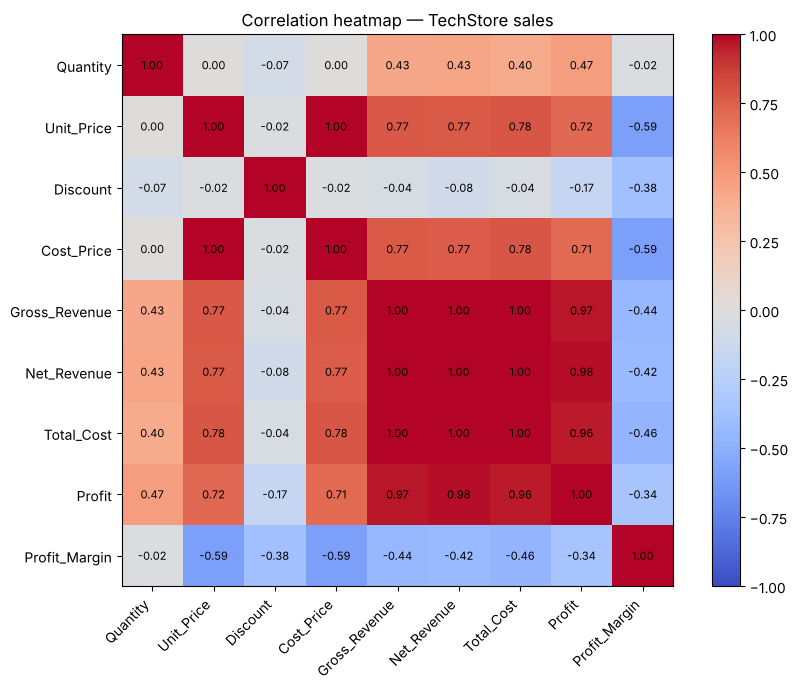

In [62]:
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im)
ax.set_title("Correlation heatmap — TechStore sales")
plt.tight_layout()
plt.show()

**Three relationships explained**
1. **Quantity ↔ Gross_Revenue (+0.43)**: more units → more revenue, but only moderately, because *price* matters more (1 laptop > 6 mice).
2. **Unit_Price ↔ Profit (+0.72)** and **Cost_Price ↔ Profit (+0.71)**: expensive products earn more profit *in TND* per sale…
3. … but **Cost_Price ↔ Profit_Margin (−0.59)**, the strongest negative correlation: expensive products earn a *smaller percentage*. **Discount ↔ Profit_Margin (−0.38)**: discounts eat the margin. **Discount ↔ Net_Revenue (−0.08)** ≈ 0: giving discounts does **not** generate bigger sales here.
- Strongest positive: Gross_Revenue ↔ Total_Cost (0.998) — both are "quantity × a price", so this is almost mechanical.

**Correlation ≠ causation.** Cost_Price and Profit are positively correlated, but raising the cost price does not *cause* more profit (it would reduce it!). The real common cause is the **product type**: expensive products (laptops) have both a high cost and a high profit per unit. Correlation only measures that two variables move together.

---
# PART 10 — Grouping and aggregation
## 18 — Sales performance by region

In [63]:
region = df.groupby("Region", observed=True).agg(
    Gross_Revenue=("Gross_Revenue", "sum"),
    Net_Revenue=("Net_Revenue", "sum"),
    Total_Profit=("Profit", "sum"),
    Avg_Profit=("Profit", "mean"),
    Avg_Order_Value=("Net_Revenue", "mean"),
    Transactions=("Order_ID", "count"),
    Quantity=("Quantity", "sum"),
    Avg_Discount=("Discount", "mean"),
    Avg_Margin=("Profit_Margin", "mean"),
).sort_values("Net_Revenue", ascending=False)
region["Revenue_Share_%"] = region["Net_Revenue"] / region["Net_Revenue"].sum() * 100
region["Profit_Rank"] = region["Total_Profit"].rank(ascending=False).astype(int)
region

,Gross_Revenue,Net_Revenue,Total_Profit,Avg_Profit,Avg_Order_Value,Transactions,Quantity,Avg_Discount,Avg_Margin,Revenue_Share_%,Profit_Rank
Region,,,,,,,,,,,
North,"155,986.74","147,569.95","50,992.95",289.73,838.47,176,380,5.65,40.56,20.70,3
West,"153,132.96","144,075.00","51,374.00",250.60,702.80,205,438,6.34,41.46,20.21,2
East,"153,693.47","143,853.18","50,254.18",225.36,645.08,223,446,6.66,41.42,20.18,4
South,"149,594.41","142,234.17","51,672.17",252.06,693.83,205,426,5.63,41.76,19.95,1
Central,"144,199.02","135,057.48","46,646.48",254.90,738.02,183,397,6.45,40.92,18.95,5


Highest revenue: North
Highest profit : South
Lowest profit  : Central


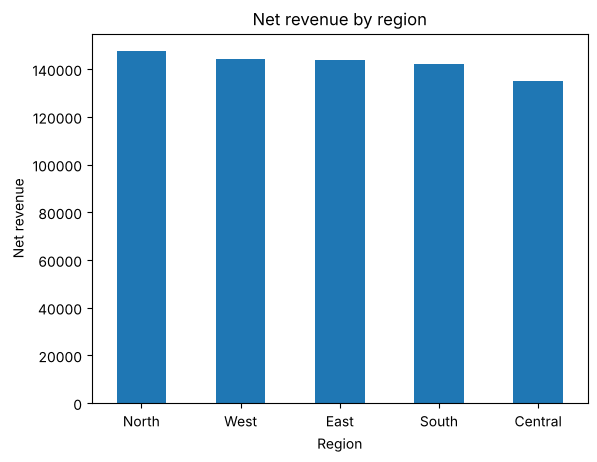

In [64]:
print("Highest revenue:", region["Net_Revenue"].idxmax())
print("Highest profit :", region["Total_Profit"].idxmax())
print("Lowest profit  :", region["Total_Profit"].idxmin())
region["Net_Revenue"].plot(kind="bar", title="Net revenue by region", ylabel="Net revenue", rot=0)
plt.show()

**Business answers — regions**
- The 5 regions are very balanced (19–21 % of revenue each). **North** has the highest net revenue (147.6 k, 20.7 %) thanks to the highest average order value (838).
- **Highest revenue ≠ highest profit:** **South** has the highest profit (51.7 k) with a lower discount (5.6 %) and the best margin (41.8 %). North is only 3rd in profit.
- **Central** is last in revenue *and* profit (46.6 k) with high discounts (6.45 %) → **region to improve** (fewer discounts, more marketing, check the team).
- More marketing investment: **South / North** (best profit and highest value per order); East has the most transactions (223) but the lowest average basket (645) → upsell opportunity.

## 19 — Product category analysis

In [65]:
cat = df.groupby("Category", observed=True).agg(
    Quantity=("Quantity", "sum"),
    Net_Revenue=("Net_Revenue", "sum"),
    Total_Profit=("Profit", "sum"),
    Avg_Selling_Price=("Unit_Price", "mean"),
    Avg_Cost_Price=("Cost_Price", "mean"),
    Avg_Discount=("Discount", "mean"),
    Transactions=("Order_ID", "count"),
    Avg_Margin=("Profit_Margin", "mean"),
).sort_values("Net_Revenue", ascending=False)
cat["Revenue_Share_%"] = cat["Net_Revenue"] / cat["Net_Revenue"].sum() * 100
cat["Revenue_Rank"] = cat["Net_Revenue"].rank(ascending=False).astype(int)
cat["Profit_Rank"] = cat["Total_Profit"].rank(ascending=False).astype(int)
cat

,Quantity,Net_Revenue,Total_Profit,Avg_Selling_Price,Avg_Cost_Price,Avg_Discount,Transactions,Avg_Margin,Revenue_Share_%,Revenue_Rank,Profit_Rank
Category,,,,,,,,,,,
Computers,343,"324,789.59","104,529.59","1,021.31",656.53,5.89,163,33.84,45.57,1,1
Smartphones,205,"116,301.90","39,861.90",616.16,380.42,6.37,95,33.66,16.32,2,2
Office Equipment,214,"68,350.98","25,370.98",351.44,205.87,6.09,92,38.02,9.59,3,3
Tablets,178,"59,103.85","23,013.85",348.93,204.36,5.19,78,38.07,8.29,4,4
Monitors,174,"53,788.74","17,683.74",330.30,208.77,6.11,81,33.91,7.55,5,5
Accessories,490,"32,411.38","15,230.38",69.57,34.48,6.55,252,51.31,4.55,6,6
Storage,170,"19,392.69","8,142.69",121.91,66.54,5.77,78,41.92,2.72,7,7
Audio,157,"15,744.61","7,195.61",105.64,54.12,5.88,74,45.43,2.21,8,8
Wearables,83,"13,373.66","5,488.66",175.13,95.00,7.18,39,41.11,1.88,9,9


Sorted by profit:
Category
Computers          104,530.00
Smartphones         39,862.00
Office Equipment    25,371.00
Tablets             23,014.00
Monitors            17,684.00
Accessories         15,230.00
Storage              8,143.00
Audio                7,196.00
Wearables            5,489.00
Networking           4,422.00
Name: Total_Profit, dtype: float64

Best category (profit)  : Computers
Least profitable        : Networking
Most units sold         : Accessories


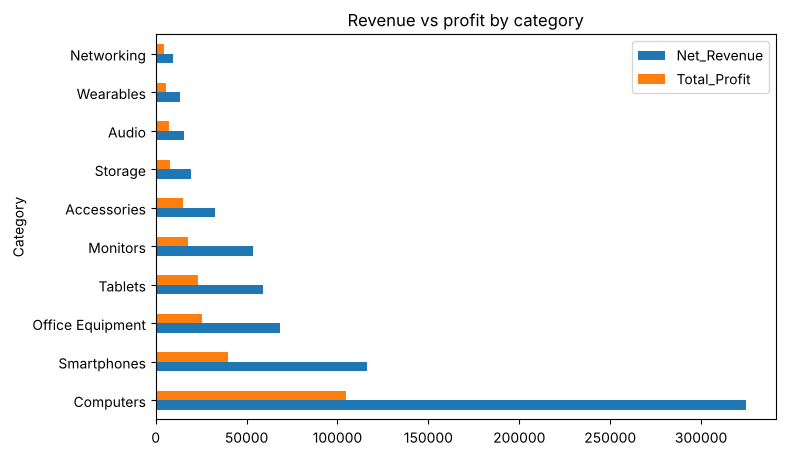

In [66]:
print("Sorted by profit:"); print(cat["Total_Profit"].sort_values(ascending=False).round(0))
print("\nBest category (profit)  :", cat["Total_Profit"].idxmax())
print("Least profitable        :", cat["Total_Profit"].idxmin())
print("Most units sold         :", cat["Quantity"].idxmax())
cat[["Net_Revenue", "Total_Profit"]].plot(kind="barh", figsize=(8, 5), title="Revenue vs profit by category")
plt.show()

**Business answers — categories**
- **Computers** is the top category in revenue (45.6 % of the total!) **and** profit (104.5 k), then Smartphones.
- **Accessories** sells the most units (490) but is only 6th in revenue: **the most popular category is not the most profitable** in TND, although it has the best margin (51 %).
- Least profitable: **Networking** (4.4 k profit, 40 transactions).
- Revenue and profit rankings are identical here.
- Marketing investment: **Computers** (biggest profit driver) and **Accessories / Audio** as add-ons to laptop sales (high margins, cheap to promote, cross-selling).

## 20 — Individual product performance

In [67]:
prod = df.groupby(["Product_ID", "Product_Name"], observed=True).agg(
    Units=("Quantity", "sum"),
    Net_Revenue=("Net_Revenue", "sum"),
    Profit=("Profit", "sum"),
    Avg_Discount=("Discount", "mean"),
    Avg_Selling_Price=("Unit_Price", "mean"),
).reset_index()
prod["Margin_%"] = prod["Profit"] / prod["Net_Revenue"] * 100
prod["Revenue_Share_%"] = prod["Net_Revenue"] / prod["Net_Revenue"].sum() * 100
prod.sort_values("Net_Revenue", ascending=False)

,Product_ID,Product_Name,Units,Net_Revenue,Profit,Avg_Discount,Avg_Selling_Price,Margin_%,Revenue_Share_%
2,P003,Gaming Laptop,93,"146,352.26","48,702.26",5.34,"1,660.09",33.28,20.53
1,P002,Laptop Air 13,78,"81,670.47","25,510.47",5.95,"1,103.70",31.24,11.46
0,P001,Laptop Pro 14,62,"72,754.03","20,054.03",6.06,"1,252.21",27.56,10.21
3,P004,Smartphone X,89,"69,808.42","23,528.42",7.27,843.12,33.70,9.79
23,P024,Projector,108,"48,822.46","17,502.46",6.63,487.93,35.85,6.85
4,P005,Smartphone Lite,116,"46,493.49","16,333.49",5.59,420.34,35.13,6.52
8,P009,Gaming Monitor 27,87,"38,961.17","11,991.17",6.34,476.62,30.78,5.47
5,P006,Tablet Plus,81,"30,517.89","11,887.89",4.21,389.49,38.95,4.28
6,P007,Tablet Mini,97,"28,585.96","11,125.96",6.12,310.39,38.92,4.01
22,P023,Graphics Tablet,110,"24,012.84","10,262.84",6.22,229.99,42.74,3.37


In [68]:
cols = ["Product_Name", "Units", "Net_Revenue", "Profit", "Margin_%"]
print("Top 5 by revenue");  display(prod.nlargest(5, "Net_Revenue")[cols])
print("Top 5 by profit");   display(prod.nlargest(5, "Profit")[cols])
print("Top 5 by quantity"); display(prod.nlargest(5, "Units")[cols])
print("5 lowest revenue");  display(prod.nsmallest(5, "Net_Revenue")[cols])

Top 5 by revenue


,Product_Name,Units,Net_Revenue,Profit,Margin_%
2,Gaming Laptop,93,"146,352.26","48,702.26",33.28
1,Laptop Air 13,78,"81,670.47","25,510.47",31.24
0,Laptop Pro 14,62,"72,754.03","20,054.03",27.56
3,Smartphone X,89,"69,808.42","23,528.42",33.70
23,Projector,108,"48,822.46","17,502.46",35.85


Top 5 by profit


,Product_Name,Units,Net_Revenue,Profit,Margin_%
2,Gaming Laptop,93,"146,352.26","48,702.26",33.28
1,Laptop Air 13,78,"81,670.47","25,510.47",31.24
3,Smartphone X,89,"69,808.42","23,528.42",33.70
0,Laptop Pro 14,62,"72,754.03","20,054.03",27.56
23,Projector,108,"48,822.46","17,502.46",35.85


Top 5 by quantity


,Product_Name,Units,Net_Revenue,Profit,Margin_%
4,Smartphone Lite,116,"46,493.49","16,333.49",35.13
22,Graphics Tablet,110,"24,012.84","10,262.84",42.74
23,Projector,108,"48,822.46","17,502.46",35.85
19,Printer,106,"19,528.52","7,868.52",40.29
10,Mechanical Keyboard,104,"8,915.20","4,235.20",47.51


5 lowest revenue


,Product_Name,Units,Net_Revenue,Profit,Margin_%
17,Phone Case,68,"1,159.40",819.40,70.67
9,Wireless Mouse,86,"2,272.63","1,240.63",54.59
11,USB-C Hub,86,"4,411.79","2,261.79",51.27
12,Webcam HD,73,"5,136.43","2,362.43",45.99
14,Bluetooth Speaker,72,"5,649.24","2,625.24",46.47


In [69]:
rev_med, margin_med = prod["Net_Revenue"].median(), prod["Margin_%"].median()
print("High revenue but LOW margin (above median revenue, below median margin):")
display(prod[(prod["Net_Revenue"] > rev_med) & (prod["Margin_%"] < margin_med)][cols])
print("Low revenue but HIGH margin:")
display(prod[(prod["Net_Revenue"] < rev_med) & (prod["Margin_%"] > margin_med)][cols])
never_sold = products_clean.loc[~products_clean["Product_ID"].isin(df["Product_ID"]), "Product_Name"]
print("Products never sold:", list(never_sold) if len(never_sold) else "none — all 24 products were sold")

High revenue but LOW margin (above median revenue, below median margin):


,Product_Name,Units,Net_Revenue,Profit,Margin_%
0,Laptop Pro 14,62,"72,754.03","20,054.03",27.56
1,Laptop Air 13,78,"81,670.47","25,510.47",31.24
2,Gaming Laptop,93,"146,352.26","48,702.26",33.28
3,Smartphone X,89,"69,808.42","23,528.42",33.70
4,Smartphone Lite,116,"46,493.49","16,333.49",35.13
5,Tablet Plus,81,"30,517.89","11,887.89",38.95
6,Tablet Mini,97,"28,585.96","11,125.96",38.92
7,Monitor 24,87,"14,827.57","5,692.57",38.39
8,Gaming Monitor 27,87,"38,961.17","11,991.17",30.78
19,Printer,106,"19,528.52","7,868.52",40.29


Low revenue but HIGH margin:


,Product_Name,Units,Net_Revenue,Profit,Margin_%
9,Wireless Mouse,86,"2,272.63","1,240.63",54.59
10,Mechanical Keyboard,104,"8,915.20","4,235.20",47.51
11,USB-C Hub,86,"4,411.79","2,261.79",51.27
12,Webcam HD,73,"5,136.43","2,362.43",45.99
13,Headphones,85,"10,095.37","4,570.37",45.27
14,Bluetooth Speaker,72,"5,649.24","2,625.24",46.47
15,External SSD 1TB,95,"12,110.85","4,985.85",41.17
16,External HDD 2TB,75,"7,281.84","3,156.84",43.35
17,Phone Case,68,"1,159.40",819.40,70.67
18,Smartwatch,83,"13,373.66","5,488.66",41.04


Products never sold: none — all 24 products were sold


**Business recommendation — 3 products to promote**
1. **Gaming Laptop** — #1 in revenue (146 k) and profit (48.7 k), 20.5 % of all revenue. Proven demand; even a small sales increase gives a big profit.
2. **Smartphone X** — #3 in profit (23.5 k) with a better margin (33.7 %) than the laptops; strong demand (89 units).
3. **Graphics Tablet** — #2 in units sold (110) with a 42.7 % margin: popular *and* profitable; promotion can turn volume into more profit. *(Alternative: Mechanical Keyboard / Headphones as cross-sell items with ~45–48 % margin.)*

**Watch out:** Laptop Pro 14 has the lowest margin (27.6 %) → avoid discounting it.

## 21 — Supplier performance

In [70]:
sup = df.groupby("Supplier", observed=True).agg(
    Products=("Product_ID", "nunique"),
    Quantity=("Quantity", "sum"),
    Net_Revenue=("Net_Revenue", "sum"),
    Total_Cost=("Total_Cost", "sum"),
    Total_Profit=("Profit", "sum"),
    Avg_Margin=("Profit_Margin", "mean"),
)
sup["Revenue_Rank"] = sup["Net_Revenue"].rank(ascending=False).astype(int)
sup["Profit_Rank"] = sup["Total_Profit"].rank(ascending=False).astype(int)
sup.sort_values("Net_Revenue", ascending=False)

,Products,Quantity,Net_Revenue,Total_Cost,Total_Profit,Avg_Margin,Revenue_Rank,Profit_Rank
Supplier,,,,,,,,
Supplier B,2,203,"170,365.10",111400,"58,965.10",37.54,1,1
Supplier A,2,140,"154,424.49",108860,"45,564.49",28.93,2,2
Supplier C,3,273,"117,461.30",76780,"40,681.31",44.33,3,3
Supplier I,3,287,"77,883.36",48090,"29,793.36",40.36,4,4
Supplier D,3,261,"72,477.51",43975,"28,502.51",39.08,5,5
Supplier E,2,174,"53,788.74",36105,"17,683.74",33.91,6,6
Supplier F,4,349,"26,115.55",14067,"12,048.55",48.45,7,7
Supplier G,3,230,"20,881.04",11323,"9,558.04",45.37,8,8
Supplier H,2,170,"19,392.69",11250,"8,142.69",41.92,9,9


**Business answers — suppliers**
- Most products: **Supplier F** (4 accessories) — but it is only 7th in revenue.
- Highest revenue and profit: **Supplier B** (Gaming Laptop + Graphics Tablet: 170 k revenue, 59 k profit), then Supplier A (laptops).
- Supplier A has the **lowest average margin (28.9 %)** → negotiate better purchase prices.
- **Keep all suppliers:** every supplier is profitable (margins 29–48 %), and the small ones (F, G, H) supply high-margin accessories that complete laptop sales. The priority is renegotiating with A, not dropping suppliers.

## 22 — Sales representative performance

In [71]:
rep = df.groupby("Sales_Rep", observed=True).agg(
    Transactions=("Order_ID", "count"),
    Quantity=("Quantity", "sum"),
    Gross_Revenue=("Gross_Revenue", "sum"),
    Net_Revenue=("Net_Revenue", "sum"),
    Total_Profit=("Profit", "sum"),
    Avg_Revenue=("Net_Revenue", "mean"),
    Avg_Profit=("Profit", "mean"),
    Avg_Discount=("Discount", "mean"),
    Avg_Margin=("Profit_Margin", "mean"),
    Std_Revenue=("Net_Revenue", "std"),
)
rep["Revenue_Share_%"] = rep["Net_Revenue"] / rep["Net_Revenue"].sum() * 100
rep["Rank_Revenue"] = rep["Net_Revenue"].rank(ascending=False).astype(int)
rep["Rank_Profit"] = rep["Total_Profit"].rank(ascending=False).astype(int)
rep["Rank_Transactions"] = rep["Transactions"].rank(ascending=False, method="min").astype(int)
# consistency = small variation of the revenue per sale relative to its mean (coefficient of variation)
rep["CV_Revenue"] = rep["Std_Revenue"] / rep["Avg_Revenue"]
rep.sort_values("Net_Revenue", ascending=False)

,Transactions,Quantity,Gross_Revenue,Net_Revenue,Total_Profit,Avg_Revenue,Avg_Profit,Avg_Discount,Avg_Margin,Std_Revenue,Revenue_Share_%,Rank_Revenue,Rank_Profit,Rank_Transactions,CV_Revenue
Sales_Rep,,,,,,,,,,,,,,,
Youssef,179,397,"152,517.20","144,278.22","51,335.22",806.02,286.79,5.70,41.42,"1,135.37",20.24,1,1,2,1.41
Ahmed,189,377,"136,779.69","128,315.61","43,658.61",678.92,231.00,6.30,40.03,930.24,18.00,2,3,1,1.37
Amine,146,308,"132,668.07","126,252.81","44,391.81",864.75,304.05,5.24,41.79,"1,415.72",17.71,3,2,6,1.64
Nour,166,357,"116,812.61","109,944.45","39,064.45",662.32,235.33,6.42,41.77,853.17,15.42,4,4,3,1.29
Sara,156,309,"116,741.27","109,583.07","38,551.07",702.46,247.12,6.86,41.55,"1,079.12",15.37,5,5,4,1.54
Maya,156,339,"101,087.76","94,415.62","33,938.62",605.23,217.56,6.44,41.20,802.38,13.25,6,6,4,1.33


In [72]:
print("Most consistent rep (lowest CV):", rep["CV_Revenue"].idxmin())
print("Correlation avg discount vs net revenue (per rep):", round(rep["Avg_Discount"].corr(rep["Net_Revenue"]), 2))

Most consistent rep (lowest CV): Nour
Correlation avg discount vs net revenue (per rep): -0.64


**Business answers — sales reps**
- Highest revenue **and** profit: **Youssef** (144.3 k revenue, 51.3 k profit, 20.2 %).
- Most transactions: **Ahmed** (189), but he is 3rd in profit: many smaller sales.
- **Amine** has the fewest transactions (146) but the highest average sale (865) and the 2nd profit → focused on big tickets.
- Most consistent (lowest coefficient of variation of the revenue per sale): **Nour**.
- **Higher discounts do not lead to better performance:** across reps, average discount vs net revenue = **−0.64** — Youssef and Amine give the *smallest* discounts (5.2–5.7 %) and sell the most; Sara and Maya give the highest (6.4–6.9 %) and are last.
- **Training:** **Maya** (lowest revenue and profit, 13.3 %) and **Sara** (highest discount rate).

## 23 — Payment method analysis

In [73]:
pay = df.groupby("Payment_Method", observed=True).agg(
    Transactions=("Order_ID", "count"),
    Net_Revenue=("Net_Revenue", "sum"),
    Total_Profit=("Profit", "sum"),
    Avg_Transaction=("Net_Revenue", "mean"),
    Avg_Discount=("Discount", "mean"),
)
pay["Share_Transactions_%"] = pay["Transactions"] / pay["Transactions"].sum() * 100
pay = pay.sort_values("Transactions", ascending=False)
print("Most popular     :", pay["Transactions"].idxmax())
print("Highest revenue  :", pay["Net_Revenue"].idxmax())
print("Highest profit   :", pay["Total_Profit"].idxmax())
pay

Most popular     : Credit Card
Highest revenue  : Credit Card
Highest profit   : Credit Card


,Transactions,Net_Revenue,Total_Profit,Avg_Transaction,Avg_Discount,Share_Transactions_%
Payment_Method,,,,,,
Credit Card,405,"300,681.62","107,189.62",742.42,6.01,40.83
Online,305,"211,973.19","74,084.19",694.99,6.02,30.75
Cash,200,"144,752.82","50,726.82",723.76,6.67,20.16
Bank Transfer,82,"55,382.15","18,939.15",675.39,6.22,8.27


---
# Extra — Time evolution, pivot tables and customers
(Objectives 15–19 of the brief: dates/time series, `pivot_table`, `crosstab`, customer behaviour, visualisations.)

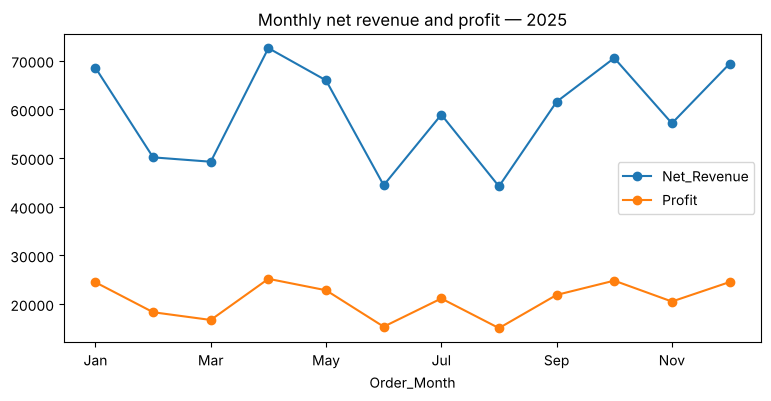

,Net_Revenue,Profit,Transactions
Order_Month,,,
Jan,"68,561.70","24,479.70",92
Feb,"50,154.86","18,331.86",80
Mar,"49,256.43","16,741.43",71
Apr,"72,603.28","25,194.28",102
May,"65,975.74","22,846.74",92
Jun,"44,429.15","15,359.15",77
Jul,"58,930.43","21,156.43",85
Aug,"44,197.65","15,066.65",68
Sep,"61,581.47","21,887.47",74


In [74]:
monthly = df.groupby("Order_Month").agg(Net_Revenue=("Net_Revenue", "sum"), Profit=("Profit", "sum"), Transactions=("Order_ID", "count"))
monthly.index = pd.to_datetime(monthly.index, format="%m").month_name().str[:3]
monthly.plot(y=["Net_Revenue", "Profit"], marker="o", figsize=(9, 4), title="Monthly net revenue and profit — 2025")
plt.show()
monthly

In [75]:
pd.pivot_table(df, values="Net_Revenue", index="Category", columns="Quarter", aggfunc="sum", margins=True, observed=True).round(0)

Quarter,1,2,3,4,All
Category,,,,,
Accessories,"9,777.00","8,706.00","6,255.00","7,674.00","32,411.00"
Audio,"4,476.00","4,125.00","3,456.00","3,688.00","15,745.00"
Computers,"67,813.00","83,900.00","79,238.00","93,839.00","324,790.00"
Monitors,"13,412.00","20,384.00","6,821.00","13,172.00","53,789.00"
Networking,995.00,"1,670.00","3,408.00","3,460.00","9,532.00"
Office Equipment,"23,929.00","16,053.00","15,819.00","12,550.00","68,351.00"
Smartphones,"22,685.00","18,763.00","28,326.00","46,527.00","116,302.00"
Storage,"5,676.00","5,898.00","3,995.00","3,825.00","19,393.00"
Tablets,"16,510.00","20,398.00","12,656.00","9,540.00","59,104.00"


In [76]:
pd.crosstab(df["Region"], df["Payment_Method"], normalize="index").mul(100).round(1)

Payment_Method,Bank Transfer,Cash,Credit Card,Online
Region,,,,
Central,6.60,16.90,47.00,29.50
East,7.20,19.70,39.50,33.60
North,10.20,25.00,37.50,27.30
South,6.80,20.00,41.00,32.20
West,10.70,19.50,39.50,30.20


In [77]:
full = df.merge(customers_clean, on="Customer_ID", how="left")
cust = full.groupby(["Customer_ID", "Customer_Name"], observed=True).agg(
    Orders=("Order_ID", "count"), Net_Revenue=("Net_Revenue", "sum"), Profit=("Profit", "sum")).reset_index()
print("Top 10 most valuable customers (net revenue):")
display(cust.nlargest(10, "Net_Revenue"))
print(full.groupby("Customer_Type", observed=True)[["Net_Revenue", "Profit"]].agg(["sum", "mean"]).round(1))
print(full.groupby("Age_Group")["Net_Revenue"].agg(["count", "sum", "mean"]).round(1))

Top 10 most valuable customers (net revenue):


,Customer_ID,Customer_Name,Orders,Net_Revenue,Profit
186,C0188,Bilel Trabelsi,8,"13,512.74","4,752.74"
159,C0161,Hatem Trabelsi,6,"13,369.01","4,474.01"
129,C0131,Tarek Haddad,7,"11,936.40","4,326.40"
176,C0178,Seif Jebali,8,"11,050.69","3,170.69"
44,C0045,Marwa Hamdi,6,"10,196.58","3,591.58"
141,C0143,Salma Mabrouk,6,"10,176.79","3,896.79"
139,C0141,Yasmine Chaabane,4,"9,407.89","2,837.89"
234,C0237,Salma Chaabane,4,"9,348.62","3,208.62"
188,C0190,Fares Mansour,4,"9,303.86","3,518.86"
5,C0006,Ines Jebali,6,"9,243.56","3,039.56"


              Net_Revenue            Profit       
                      sum   mean        sum   mean
Customer_Type                                     
New            289,423.40 765.70 103,685.40 274.30
Returning      423,366.40 689.50 147,254.40 239.80
           count        sum   mean
Age_Group                         
Adult        394 291,750.10 740.50
Senior       383 270,390.90 706.00
Young        215 150,648.80 700.70


In [78]:
# Export the clean / enriched data (index=False!)
os.makedirs("output", exist_ok=True)
sales_clean.to_csv("output/sales_clean.csv", index=False)
customers_clean.to_csv("output/customers_clean.csv", index=False)
df.to_csv("output/techstore_sales_enriched.csv", index=False)
check = pd.read_csv("output/techstore_sales_enriched.csv", parse_dates=["Order_Date"])
print("Reloaded:", check.shape, "| Order_Date dtype:", check["Order_Date"].dtype)

Reloaded: (992, 36) | Order_Date dtype: datetime64[us]


---
# Final report — key findings and recommendations

| Question from management | Answer |
|---|---|
| Revenue generated | **≈ 712.8 k** net revenue (≈ 756.6 k before discounts) for 992 clean transactions in 2025 |
| Profit | **≈ 250.9 k** → global margin **35.2 %**; no loss-making sale |
| Most profitable products | Gaming Laptop, Laptop Air 13, Smartphone X; **Computers = 45.6 % of revenue** |
| Best regions | North (revenue), **South (profit)**; Central is last on both |
| Most valuable customers | C0188 Bilel Trabelsi (13.5 k), C0161 Hatem Trabelsi (13.4 k), C0131 Tarek Haddad (11.9 k); Returning customers = 59 % of revenue |
| Best sales rep | **Youssef** (revenue & profit); Ahmed has the most transactions |
| Discounts vs profit | margin falls from **44.9 % → 35.0 %** between no discount and high discount, and discounts do **not** increase net revenue |
| Evolution in time | stable year, peaks in **April, October, December, January** (≈ 69–73 k), lows in **June and August** (≈ 44 k) |

### Recommendations
1. **Limit discounts** (especially >10 %) — they reduce margin without bringing more revenue. Set a discount policy per rep.
2. **Push Computers + accessory bundles**: laptops bring the profit, accessories/audio bring the margin (45–70 %) → cross-sell.
3. **Renegotiate with Supplier A** (lowest margin, 28.9 %) and avoid discounting the Laptop Pro 14.
4. **Improve Central region**: lowest profit and high discounts → targeted marketing and coaching.
5. **Train Maya and Sara**, share Youssef's/Amine's practices (fewer discounts, bigger baskets).
6. **Plan summer campaigns** (June / August are the weakest months) and prepare stock for April, October and the end of the year.
7. **Loyalty programme** for top customers and returning customers (61 % of the base).

**Data-quality note:** raw files had 45 sales rows with missing values, 3 duplicated transactions, 12 missing ages and 8 missing cities; all decisions are documented in Part 5.